## Code Source: Orang 1

In [1]:
# 4.2 PENGUMPULAN DAN PEMAHAMAN DATA

# Mengimpor library
import pandas as pd
from pathlib import Path

# Menentukan lokasi dataset
csv_path = Path(r"C:\Users\melin\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Alternatif jika working directory berada di folder utama
if not csv_path.exists():
    csv_path = Path("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Membaca dataset
df = pd.read_csv(csv_path)

# Menampilkan ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Menampilkan 5 baris pertama
display(df.head())

Jumlah baris dan kolom: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Memeriksa tipe data setiap kolom
df.info()

# Memeriksa jumlah missing values
display(df.isnull().sum().to_frame("Missing Values"))

# Memeriksa duplikasi
print("Duplikasi baris:", df.duplicated().sum())
print("Duplikasi customerID:", df["customerID"].duplicated().sum())

# Memeriksa distribusi target
display(df["Churn"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplikasi baris: 0
Duplikasi customerID: 0


No     5174
Yes    1869
Name: Churn, dtype: int64

In [3]:
# 4.2 - PEMERIKSAAN NILAI KOSONG TERSEMBUNYI

# Memeriksa string kosong atau hanya spasi
blank_counts = {
    col: df[col].astype("string").str.strip().eq("").sum()
    for col in df.select_dtypes(include="object").columns
}

blank_report = pd.DataFrame(
    blank_counts.items(),
    columns=["Column", "Blank Values"]
)

display(blank_report)

# Menguji konversi TotalCharges menjadi numerik
total_numeric = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

# Menampilkan baris yang gagal dikonversi
invalid_total = df.loc[
    total_numeric.isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

print("Jumlah TotalCharges tidak valid:", len(invalid_total))
display(invalid_total)

# Memeriksa tenure pelanggan tersebut
print("Distribusi tenure:")
display(invalid_total["tenure"].value_counts())

,Column,Blank Values
0,customerID,0
1,gender,0
2,Partner,0
3,Dependents,0
4,PhoneService,0
5,MultipleLines,0
6,InternetService,0
7,OnlineSecurity,0
8,OnlineBackup,0
9,DeviceProtection,0


Jumlah TotalCharges tidak valid: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Distribusi tenure:


0    11
Name: tenure, dtype: int64

In [4]:
# 4.3 - DATA PREPROCESSING

import numpy as np

# Salin data asli agar tidak berubah
clean = df.copy()

# Membersihkan spasi pada variabel teks
for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].str.strip()

# Konversi TotalCharges
clean["TotalCharges"] = pd.to_numeric(
    clean["TotalCharges"],
    errors="coerce"
)

# Identifikasi nilai kosong
missing_total = clean["TotalCharges"].isna()

# Isi nol hanya jika tenure = 0
valid_zero = missing_total & (clean["tenure"] == 0)

clean.loc[valid_zero, "TotalCharges"] = 0.0

print("TotalCharges diperbaiki:", valid_zero.sum())

# Hentikan proses jika masih ada nilai tidak valid
if clean["TotalCharges"].isna().any():
    raise ValueError(
        "Masih ada TotalCharges kosong yang perlu diperiksa."
    )

# Pastikan customerID unik
if clean["customerID"].duplicated().any():
    raise ValueError("Terdapat customerID duplikat.")

# Mengubah status churn ke representasi biner
clean["ChurnBinary"] = clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

if clean["ChurnBinary"].isna().any():
    raise ValueError("Terdapat kategori Churn tidak dikenal.")

# Feature engineering: TenureGroup
clean["TenureGroup"] = pd.cut(
    clean["tenure"],
    bins=[-1, 12, 24, 48, np.inf],
    labels=["0-12", "13-24", "25-48", "49+"]
)

# Menghitung layanan tambahan aktif
additional_services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

clean["NumAdditionalServices"] = (
    clean[additional_services] == "Yes"
).sum(axis=1)

# Menghitung seluruh komponen layanan aktif
clean["NumTotalServices"] = (
    clean["NumAdditionalServices"]
    + (clean["PhoneService"] == "Yes").astype(int)
    + (clean["MultipleLines"] == "Yes").astype(int)
    + (clean["InternetService"] != "No").astype(int)
)

# Mengidentifikasi kontrak jangka panjang
clean["HasLongTermContract"] = clean["Contract"].isin(
    ["One year", "Two year"]
).astype(int)

# Kelompok biaya untuk EDA deskriptif saja
clean["MonthlyChargeGroup"] = pd.qcut(
    clean["MonthlyCharges"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

print("Ukuran data setelah preprocessing:", clean.shape)
print("Total missing values:", clean.isna().sum().sum())

display(clean.head())

TotalCharges diperbaiki: 11
Ukuran data setelah preprocessing: (7043, 27)
Total missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBinary,TenureGroup,NumAdditionalServices,NumTotalServices,HasLongTermContract,MonthlyChargeGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Electronic check,29.85,29.85,No,0,0-12,1,2,0,Q1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Mailed check,56.95,1889.50,No,0,25-48,2,4,1,Q2
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Mailed check,53.85,108.15,Yes,1,0-12,2,4,0,Q2
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Bank transfer (automatic),42.30,1840.75,No,0,25-48,3,4,1,Q2
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Electronic check,70.70,151.65,Yes,1,0-12,0,2,0,Q3


In [5]:
# EKSPOR DATA PREPROCESSING

from pathlib import Path

# Folder hasil preprocessing
output_dir = csv_path.parent.parent / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Dataset utama untuk EDA, statistik, dan klasifikasi
clean.to_csv(
    output_dir / "telco_cleaned.csv",
    index=False
)

# Dataset khusus clustering (belum distandardisasi)
cluster_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumAdditionalServices",
    "NumTotalServices"
]

clean[
    ["customerID"] + cluster_features
].to_csv(
    output_dir / "telco_clustering_features.csv",
    index=False
)

# Ringkasan kualitas data
quality_report = pd.DataFrame({
    "Indicator": [
        "Jumlah pelanggan",
        "Jumlah variabel",
        "Duplikasi customerID",
        "Missing TotalCharges",
        "Missing keseluruhan"
    ],
    "Before": [
        len(df),
        df.shape[1],
        df["customerID"].duplicated().sum(),
        total_numeric.isna().sum(),
        df.isna().sum().sum()
    ],
    "After": [
        len(clean),
        clean.shape[1],
        clean["customerID"].duplicated().sum(),
        clean["TotalCharges"].isna().sum(),
        clean.isna().sum().sum()
    ]
})

quality_report.to_csv(
    output_dir / "preprocessing_report.csv",
    index=False
)

print("Semua file berhasil disimpan di:")
print(output_dir.resolve())
display(quality_report)

Semua file berhasil disimpan di:
C:\Users\melin\processed


,Indicator,Before,After
0,Jumlah pelanggan,7043,7043
1,Jumlah variabel,21,27
2,Duplikasi customerID,0,0
3,Missing TotalCharges,11,0
4,Missing keseluruhan,0,0


In [6]:
# CELL 6 - FINAL DATA QUALITY REPORT

# Menghitung nilai kosong termasuk string berisi spasi
blank_before = sum(
    df[col].astype("string").str.strip().eq("").sum()
    for col in df.select_dtypes(include="object").columns
)

missing_before = df.isna().sum().sum() + blank_before
missing_after = clean.isna().sum().sum()

quality_report = pd.DataFrame({
    "Indicator": [
        "Jumlah pelanggan",
        "Jumlah variabel",
        "Duplikasi customerID",
        "TotalCharges kosong/tidak valid",
        "Missing keseluruhan termasuk blank"
    ],
    "Before": [
        len(df),
        df.shape[1],
        df["customerID"].duplicated().sum(),
        total_numeric.isna().sum(),
        missing_before
    ],
    "After": [
        len(clean),
        clean.shape[1],
        clean["customerID"].duplicated().sum(),
        clean["TotalCharges"].isna().sum(),
        missing_after
    ]
})

quality_report.to_csv(
    output_dir / "preprocessing_report.csv",
    index=False
)

display(quality_report)

,Indicator,Before,After
0,Jumlah pelanggan,7043,7043
1,Jumlah variabel,21,27
2,Duplikasi customerID,0,0
3,TotalCharges kosong/tidak valid,11,0
4,Missing keseluruhan termasuk blank,11,0


In [7]:
# CELL 7 - DATA DICTIONARY

descriptions = {
    "customerID": "Identitas unik pelanggan",
    "gender": "Jenis kelamin pelanggan",
    "SeniorCitizen": "Indikator pelanggan senior (0/1)",
    "Partner": "Status memiliki pasangan",
    "Dependents": "Status memiliki tanggungan",
    "tenure": "Lama berlangganan dalam bulan",
    "PhoneService": "Status layanan telepon",
    "MultipleLines": "Status layanan beberapa saluran telepon",
    "InternetService": "Jenis layanan internet",
    "OnlineSecurity": "Status layanan keamanan online",
    "OnlineBackup": "Status layanan pencadangan online",
    "DeviceProtection": "Status perlindungan perangkat",
    "TechSupport": "Status dukungan teknis",
    "StreamingTV": "Status layanan streaming TV",
    "StreamingMovies": "Status layanan streaming film",
    "Contract": "Jenis kontrak pelanggan",
    "PaperlessBilling": "Status tagihan tanpa kertas",
    "PaymentMethod": "Metode pembayaran",
    "MonthlyCharges": "Biaya bulanan pelanggan",
    "TotalCharges": "Akumulasi tagihan pelanggan",
    "Churn": "Status churn: Yes atau No",
    "ChurnBinary": "Status churn numerik: Yes=1, No=0",
    "TenureGroup": "Kelompok lama berlangganan",
    "NumAdditionalServices": "Jumlah layanan tambahan aktif",
    "NumTotalServices": "Jumlah komponen layanan aktif",
    "HasLongTermContract": "Indikator kontrak jangka panjang",
    "MonthlyChargeGroup": "Kelompok kuartil biaya bulanan"
}

data_dictionary = pd.DataFrame({
    "Variable": clean.columns,
    "DataType": [str(clean[c].dtype) for c in clean.columns],
    "Description": [
        descriptions.get(c, "Perlu dokumentasi")
        for c in clean.columns
    ],
    "MissingValues": [
        int(clean[c].isna().sum())
        for c in clean.columns
    ]
})

data_dictionary.to_csv(
    output_dir / "data_dictionary.csv",
    index=False
)

display(data_dictionary)

print("Jumlah variabel:", len(data_dictionary))

,Variable,DataType,Description,MissingValues
0,customerID,object,Identitas unik pelanggan,0
1,gender,object,Jenis kelamin pelanggan,0
2,SeniorCitizen,int64,Indikator pelanggan senior (0/1),0
3,Partner,object,Status memiliki pasangan,0
4,Dependents,object,Status memiliki tanggungan,0
5,tenure,int64,Lama berlangganan dalam bulan,0
6,PhoneService,object,Status layanan telepon,0
7,MultipleLines,object,Status layanan beberapa saluran telepon,0
8,InternetService,object,Jenis layanan internet,0
9,OnlineSecurity,object,Status layanan keamanan online,0


Jumlah variabel: 27


In [8]:
# CELL 8 - FINAL VALIDATION

# Baca kembali file yang sudah diekspor
final_df = pd.read_csv(
    output_dir / "telco_cleaned.csv"
)

cluster_df = pd.read_csv(
    output_dir / "telco_clustering_features.csv"
)

# Pemeriksaan otomatis
assert len(final_df) == len(df)
assert final_df["customerID"].is_unique
assert final_df.isna().sum().sum() == 0
assert final_df["ChurnBinary"].isin([0, 1]).all()
assert len(cluster_df) == len(final_df)
assert "Churn" not in cluster_df.columns
assert "ChurnBinary" not in cluster_df.columns

# Periksa jumlah data target
print("Distribusi Churn:")
display(final_df["Churn"].value_counts())

print("Ukuran dataset utama:", final_df.shape)
print("Ukuran dataset clustering:", cluster_df.shape)

print("\nVALIDASI BERHASIL")
print("Dataset siap dibagikan kepada anggota kelompok.")

Distribusi Churn:


No     5174
Yes    1869
Name: Churn, dtype: int64

Ukuran dataset utama: (7043, 27)
Ukuran dataset clustering: (7043, 6)

VALIDASI BERHASIL
Dataset siap dibagikan kepada anggota kelompok.


## Code Source: Orang 2

In [9]:
#Setup dan Pemuatan Data
import warnings
warnings.filterwarnings("ignore")

import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RANDOM_STATE = 42
ALPHA = 0.05
PAL = {"No": "#4C78A8", "Yes": "#E4572E"}   # warna konsisten: non-churn biru, churn oranye-merah

# --- lokasi folder (sama polanya dengan notebook Orang 1)
MANUAL_PROCESSED = Path(r"C:\Users\melin\processed")

candidates = [Path("../data/processed"), Path("data/processed")]
if MANUAL_PROCESSED is not None:
    candidates.insert(0, Path(MANUAL_PROCESSED))

for cand in candidates:
    if (cand / "telco_cleaned.csv").exists():
        PROCESSED = cand
        break
else:
    raise FileNotFoundError(
        f"telco_cleaned.csv tidak ditemukan. Working dir: {Path.cwd()}. "
        "Isi MANUAL_PROCESSED dengan folder tempat file itu berada."
    )

# figures/ dan tables/ dibuat di folder yang sama dengan 'processed'
# (struktur standar data/processed -> root proyek; kalau tidak, di samping 'processed')
p = PROCESSED.resolve()
ROOT = p.parent.parent if p.parent.name == "data" else p.parent
FIG = ROOT / "figures"
TAB = ROOT / "tables"
FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def save_tab(frame, name, index=True):
    frame.to_csv(TAB / f"{name}.csv", index=index)

print("Data   :", PROCESSED.resolve())
print("Figures:", FIG.resolve())
print("Tables :", TAB.resolve())

Data   : C:\Users\melin\processed
Figures: C:\Users\melin\figures
Tables : C:\Users\melin\tables


In [10]:
df = pd.read_csv(PROCESSED / "telco_cleaned.csv")

# CSV tidak menyimpan tipe kategori terurut -> dipulihkan di sini
tenure_order = ["0-12", "13-24", "25-48", "49+"]
charge_order = ["Q1", "Q2", "Q3", "Q4"]
df["TenureGroup"] = pd.Categorical(df["TenureGroup"], categories=tenure_order, ordered=True)
df["MonthlyChargeGroup"] = pd.Categorical(df["MonthlyChargeGroup"], categories=charge_order, ordered=True)
df["Contract"] = pd.Categorical(df["Contract"], categories=["Month-to-month", "One year", "Two year"], ordered=True)

# SeniorCitizen (0/1) -> label kategori untuk analisis kategorikal
df["Senior"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = ["gender", "Senior", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
            "PaperlessBilling", "PaymentMethod"]

overall_churn = df["ChurnBinary"].mean() * 100
print("Ukuran data:", df.shape)
print(f"Churn rate keseluruhan: {overall_churn:.2f}%  "
      f"({df['ChurnBinary'].sum():,} dari {len(df):,} pelanggan)")
assert df["customerID"].is_unique and df.isna().sum().sum() == 0
df.head()

Ukuran data: (7043, 28)
Churn rate keseluruhan: 26.54%  (1,869 dari 7,043 pelanggan)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBinary,TenureGroup,NumAdditionalServices,NumTotalServices,HasLongTermContract,MonthlyChargeGroup,Senior
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.8500,No,0,0-12,1,2,0,Q1,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,"1,889.5000",No,0,25-48,2,4,1,Q2,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.1500,Yes,1,0-12,2,4,0,Q2,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,"1,840.7500",No,0,25-48,3,4,1,Q2,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.6500,Yes,1,0-12,0,2,0,Q3,No


---
## 4.4 Exploratory Data Analysis (EDA)

### A. Univariate Analysis
*Pertanyaan: seperti apa karakteristik umum pelanggan dalam dataset?*

In [11]:
# Statistik deskriptif variabel numerik
desc = df[num_cols + ["NumAdditionalServices", "NumTotalServices"]].describe().T
desc["median"] = df[desc.index].median()
desc["IQR"] = df[desc.index].quantile(.75) - df[desc.index].quantile(.25)
desc["skew"] = df[desc.index].skew()
desc = desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "IQR", "skew"]]
save_tab(desc, "eda_descriptive_numeric")
desc

,count,mean,median,std,min,25%,75%,max,IQR,skew
tenure,"7,043.0000",32.3711,29.0000,24.5595,0.0000,9.0000,55.0000,72.0000,46.0000,0.2395
MonthlyCharges,"7,043.0000",64.7617,70.3500,30.0900,18.2500,35.5000,89.8500,118.7500,54.3500,-0.2205
TotalCharges,"7,043.0000","2,279.7343","1,394.5500","2,266.7945",0.0000,398.5500,"3,786.6000","8,684.8000","3,388.0500",0.9632
NumAdditionalServices,"7,043.0000",2.0379,2.0000,1.8477,0.0000,0.0000,3.0000,6.0000,3.0000,0.4521
NumTotalServices,"7,043.0000",4.1462,4.0000,2.3127,1.0000,2.0000,6.0000,9.0000,4.0000,0.2219


In [12]:
# Deteksi outlier dengan aturan IQR (1.5 x IQR) -> hanya dilaporkan, tidak dihapus
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"Variable": c, "Lower fence": lo, "Upper fence": hi, "N outlier": n_out,
                 "% outlier": n_out / len(df) * 100})
outlier_tbl = pd.DataFrame(rows).set_index("Variable")
save_tab(outlier_tbl, "eda_outlier_iqr")
outlier_tbl

,Lower fence,Upper fence,N outlier,% outlier
Variable,,,,
tenure,-60.0000,124.0000,0,0.0000
MonthlyCharges,-46.0250,171.3750,0,0.0000
TotalCharges,"-4,683.5250","8,868.6750",0,0.0000


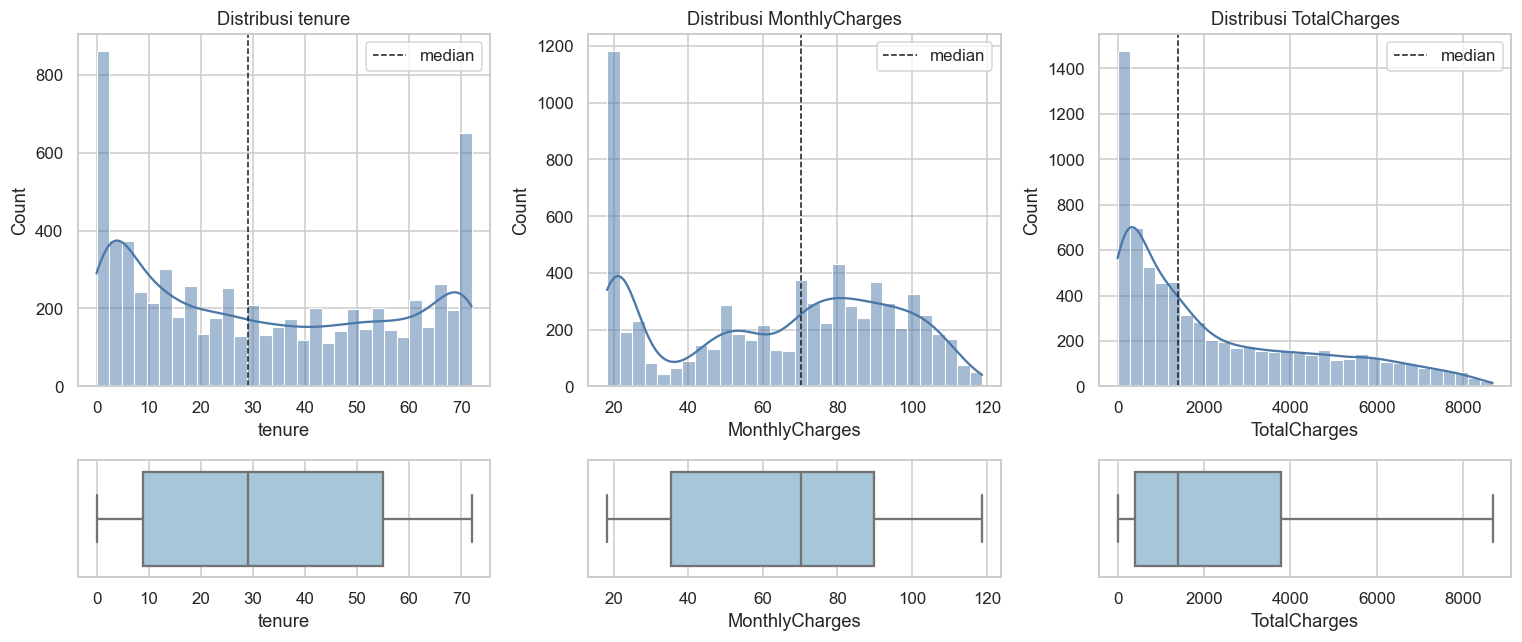

In [13]:
# Histogram + boxplot variabel numerik
fig, axes = plt.subplots(2, 3, figsize=(14, 6), gridspec_kw={"height_ratios": [3, 1]})
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=30, kde=True, color="#4C78A8", ax=axes[0, i])
    axes[0, i].axvline(df[c].median(), color="k", ls="--", lw=1, label="median")
    axes[0, i].set_title(f"Distribusi {c}")
    axes[0, i].legend()
    sns.boxplot(x=df[c], color="#9ecae1", ax=axes[1, i])
plt.tight_layout()
save_fig("eda_univariate_numeric")
plt.show()

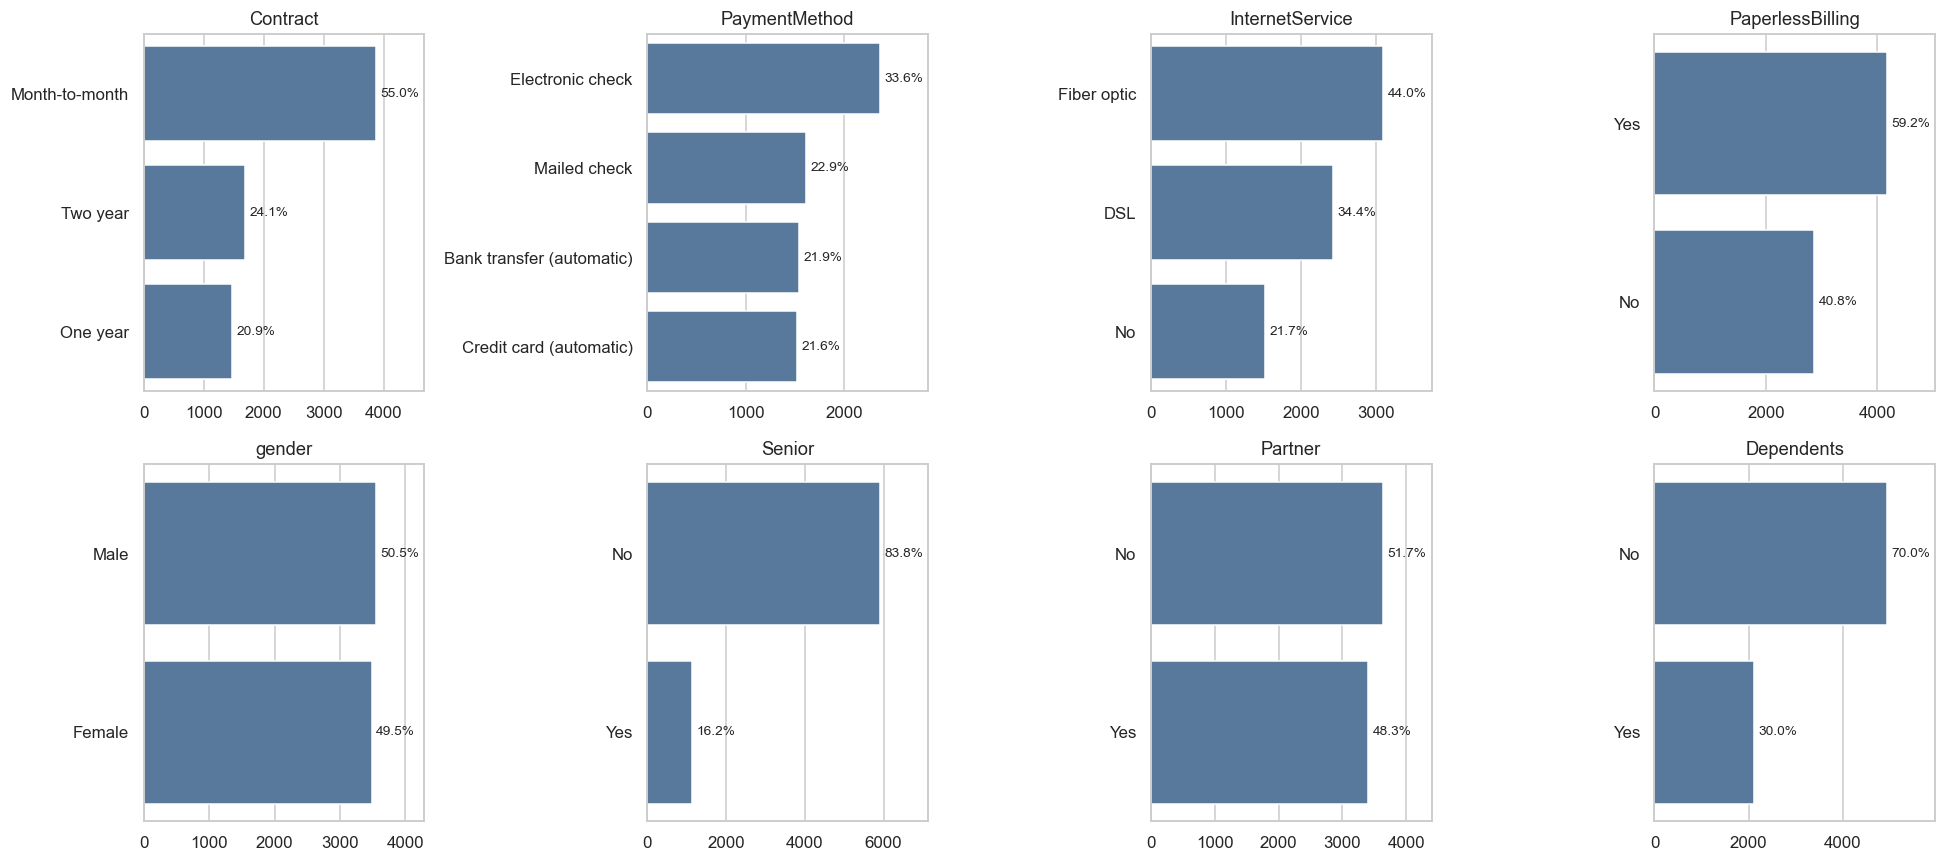

In [14]:
# Distribusi variabel kategorikal utama
focus = ["Contract", "PaymentMethod", "InternetService", "PaperlessBilling",
         "gender", "Senior", "Partner", "Dependents"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), focus):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, color="#4C78A8", ax=ax)
    for p in ax.patches:
        ax.annotate(f"{p.get_width() / len(df) * 100:.1f}%", (p.get_width(), p.get_y() + p.get_height() / 2),
                    ha="left", va="center", fontsize=9, xytext=(3, 0), textcoords="offset points")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.15)
plt.tight_layout()
save_fig("eda_univariate_categorical")
plt.show()

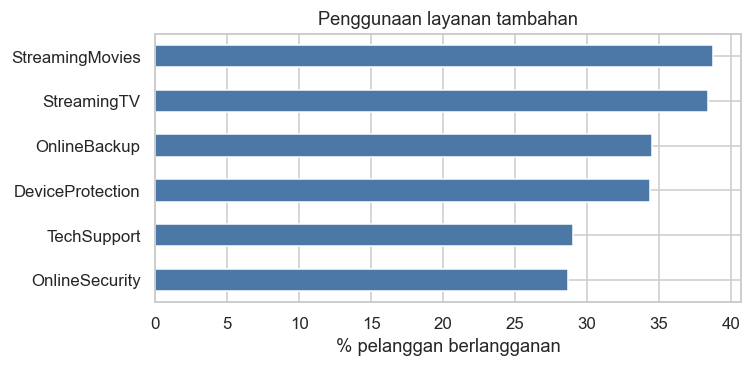

Pelanggan tanpa layanan internet: 21.7%


In [15]:
# Distribusi layanan tambahan (persentase pelanggan yang berlangganan)
svc = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
svc_share = pd.Series({s: (df[s] == "Yes").mean() * 100 for s in svc}).sort_values()
svc_share.plot.barh(color="#4C78A8", figsize=(7, 3.5))
plt.xlabel("% pelanggan berlangganan"); plt.title("Penggunaan layanan tambahan")
plt.tight_layout(); save_fig("eda_additional_services_share"); plt.show()

# Catatan: persentase di atas dihitung dari SELURUH pelanggan.
# Pelanggan tanpa internet ("No internet service") otomatis tidak bisa memakai layanan ini.
print("Pelanggan tanpa layanan internet:", f"{(df['InternetService'] == 'No').mean() * 100:.1f}%")

### B. Bivariate Analysis — hubungan tiap variabel dengan churn
Yang dibandingkan adalah **churn rate per kategori**, bukan jumlah pelanggan churn, karena ukuran kelompok berbeda-beda.

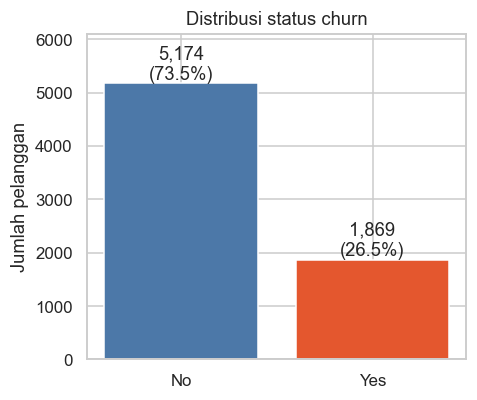

Rasio kelas No:Yes = 2.77 : 1  -> kelas tidak seimbang (penting untuk Orang 3)


In [16]:
# 1) Distribusi churn
cnt = df["Churn"].value_counts()
fig, ax = plt.subplots(figsize=(4.5, 3.8))
bars = ax.bar(cnt.index, cnt.values, color=[PAL[k] for k in cnt.index])
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, cnt.max() * 1.18); ax.set_title("Distribusi status churn"); ax.set_ylabel("Jumlah pelanggan")
plt.tight_layout(); save_fig("eda_churn_distribution"); plt.show()
print(f"Rasio kelas No:Yes = {cnt['No'] / cnt['Yes']:.2f} : 1  -> kelas tidak seimbang (penting untuk Orang 3)")

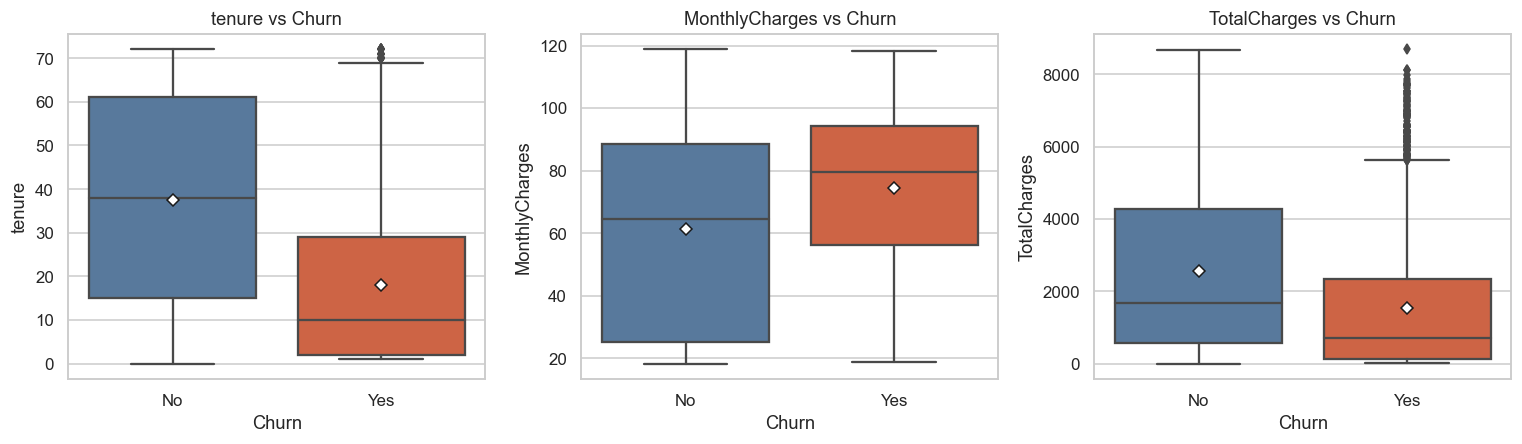

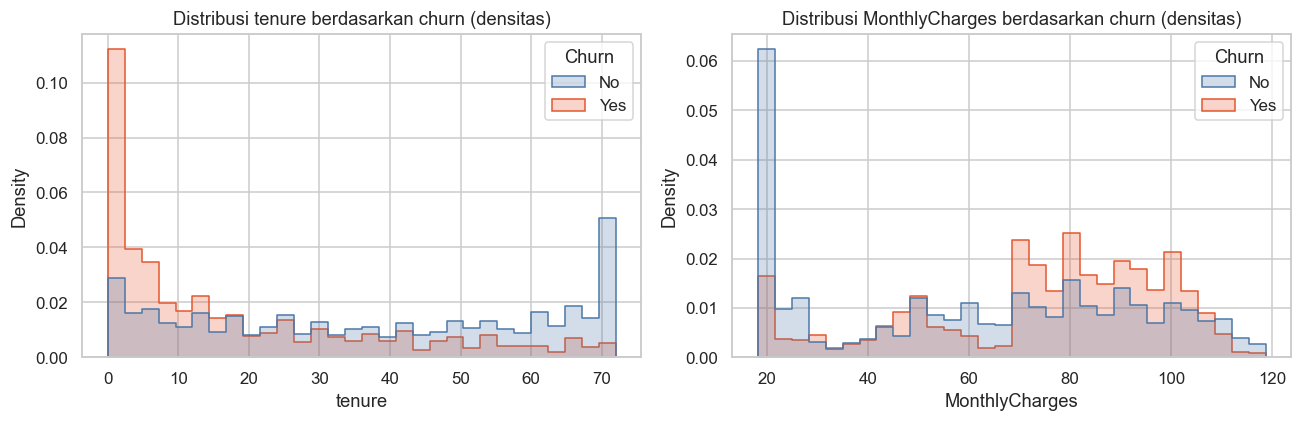

In [17]:
# 2) Variabel numerik vs churn
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, order=["No", "Yes"], palette=PAL, ax=ax, showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "k"})
    ax.set_title(f"{c} vs Churn")
plt.tight_layout(); save_fig("eda_boxplot_numeric_vs_churn"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, ["tenure", "MonthlyCharges"]):
    sns.histplot(data=df, x=c, hue="Churn", bins=30, stat="density", common_norm=False,
                 palette=PAL, element="step", ax=ax)
    ax.set_title(f"Distribusi {c} berdasarkan churn (densitas)")
plt.tight_layout(); save_fig("eda_hist_numeric_by_churn"); plt.show()

In [18]:
# 3) Fungsi bantu: tabel churn rate per kategori
def churn_rate_table(col):
    t = (df.groupby(col, observed=True)["ChurnBinary"]
           .agg(n="size", churned="sum", churn_rate="mean"))
    t["churn_rate"] *= 100
    lo, hi = proportion_confint(t["churned"], t["n"], method="wilson")
    t["CI95_low"], t["CI95_high"] = lo * 100, hi * 100
    return t

# Ringkasan: seluruh kategori seluruh variabel (long format)
parts = []
for c in cat_cols + ["TenureGroup", "MonthlyChargeGroup", "NumAdditionalServices"]:
    t = churn_rate_table(c).reset_index().rename(columns={c: "Category"})
    t.insert(0, "Variable", c)
    t["Category"] = t["Category"].astype(str)
    parts.append(t)
churn_by_cat = pd.concat(parts, ignore_index=True)
save_tab(churn_by_cat, "eda_churn_rate_by_category", index=False)

# Sorotan: kategori dengan churn rate tertinggi & terendah per variabel
hi = churn_by_cat.loc[churn_by_cat.groupby("Variable")["churn_rate"].idxmax(), ["Variable", "Category", "churn_rate", "n"]]
lo = churn_by_cat.loc[churn_by_cat.groupby("Variable")["churn_rate"].idxmin(), ["Variable", "Category", "churn_rate", "n"]]
highlight = hi.merge(lo, on="Variable", suffixes=("_tertinggi", "_terendah"))
highlight["selisih (poin %)"] = highlight["churn_rate_tertinggi"] - highlight["churn_rate_terendah"]
highlight.sort_values("selisih (poin %)", ascending=False).reset_index(drop=True)

,Variable,Category_tertinggi,churn_rate_tertinggi,n_tertinggi,Category_terendah,churn_rate_terendah,n_terendah,selisih (poin %)
0,NumAdditionalServices,1,45.7557,966,6,5.2817,284,40.4740
1,Contract,Month-to-month,42.7097,3875,Two year,2.8319,1695,39.8778
2,TenureGroup,0-12,47.4382,2186,49+,9.5132,2239,37.9251
3,InternetService,Fiber optic,41.8928,3096,No,7.4050,1526,34.4878
4,OnlineSecurity,No,41.7667,3498,No internet service,7.4050,1526,34.3617
5,TechSupport,No,41.6355,3473,No internet service,7.4050,1526,34.2305
6,OnlineBackup,No,39.9288,3088,No internet service,7.4050,1526,32.5238
7,DeviceProtection,No,39.1276,3095,No internet service,7.4050,1526,31.7226
8,PaymentMethod,Electronic check,45.2854,2365,Credit card (automatic),15.2431,1522,30.0423
9,StreamingMovies,No,33.6804,2785,No internet service,7.4050,1526,26.2755


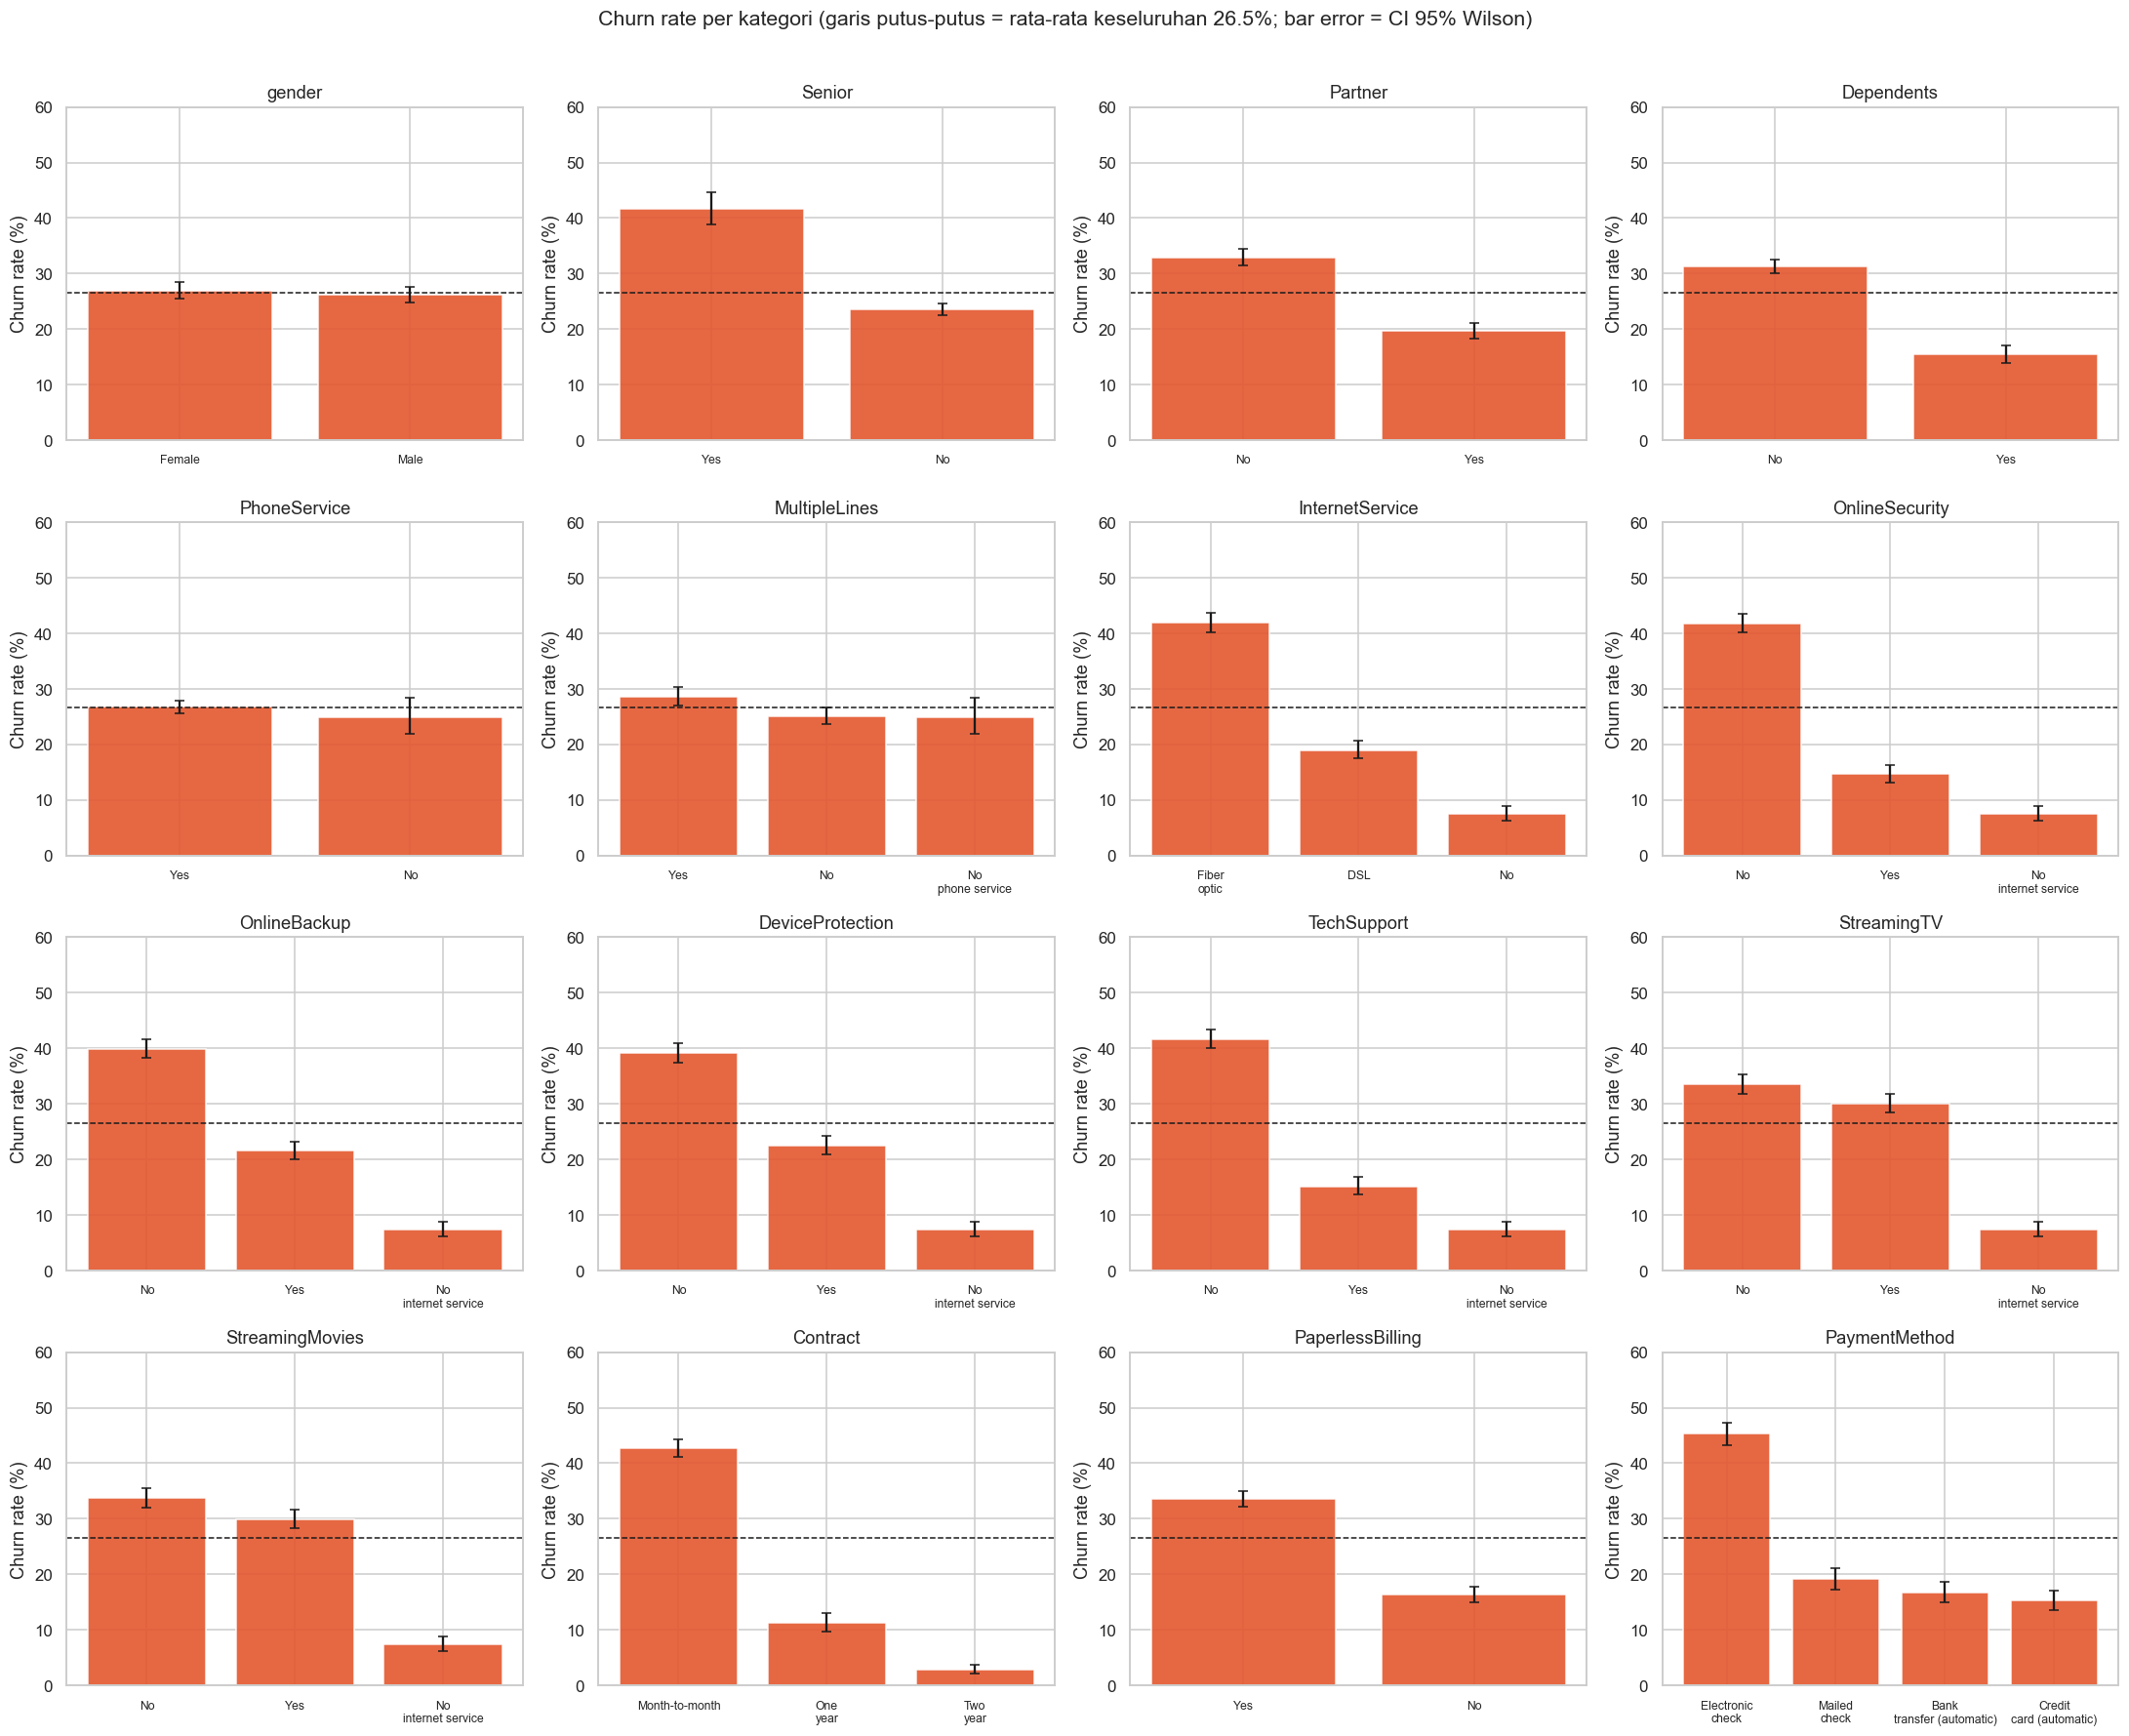

In [19]:
# 4) Churn rate per kategori (grid seluruh variabel kategorikal)
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, c in zip(axes.ravel(), cat_cols):
    t = churn_rate_table(c)
    t = t.sort_values("churn_rate", ascending=False) if c != "Contract" else t
    ax.bar(range(len(t)), t["churn_rate"], color="#E4572E",
           yerr=[t["churn_rate"] - t["CI95_low"], t["CI95_high"] - t["churn_rate"]], capsize=3, alpha=.9)
    ax.axhline(overall_churn, color="k", ls="--", lw=1)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i).replace(" ", "\n", 1) for i in t.index], fontsize=8)
    ax.set_title(c); ax.set_ylabel("Churn rate (%)"); ax.set_ylim(0, 60)
fig.suptitle(f"Churn rate per kategori (garis putus-putus = rata-rata keseluruhan {overall_churn:.1f}%; bar error = CI 95% Wilson)",
             y=1.01, fontsize=14)
plt.tight_layout(); save_fig("eda_churn_rate_all_categoricals"); plt.show()

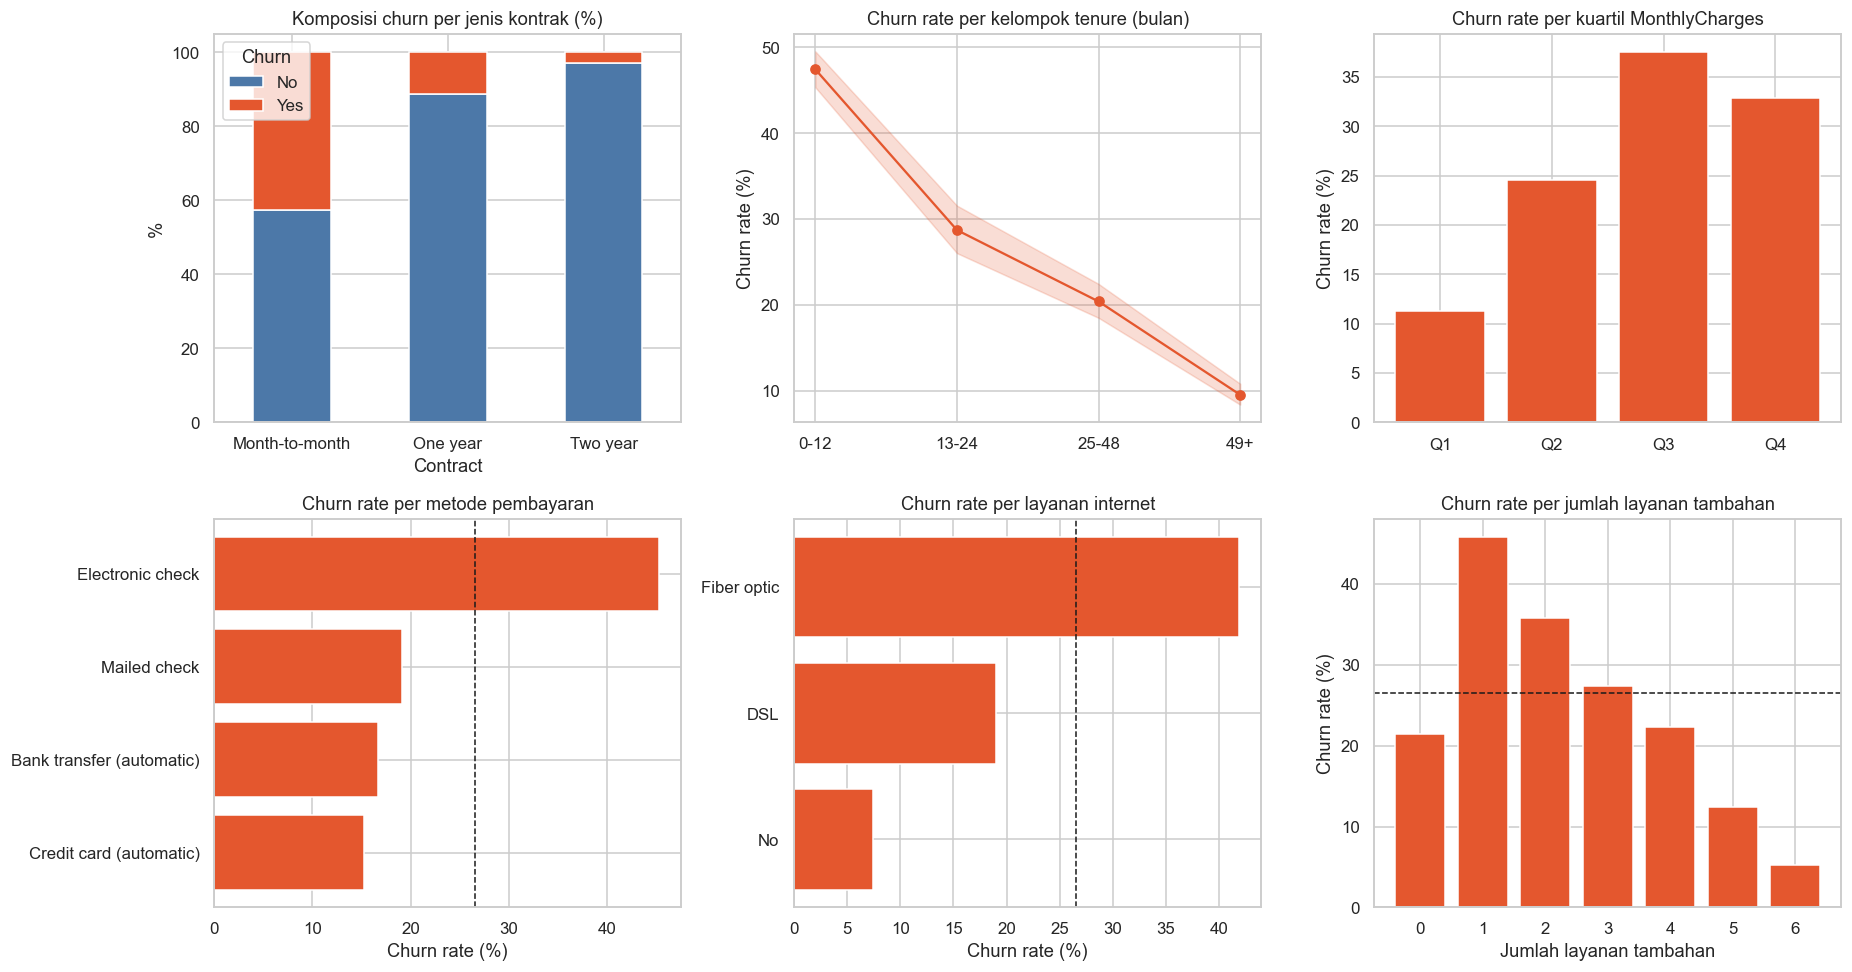

In [20]:
# 5) Pertanyaan penelitian utama: kontrak, tenure, biaya, layanan, pembayaran
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# Kontrak (stacked 100%)
ct = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
ct[["No", "Yes"]].plot.bar(stacked=True, color=[PAL["No"], PAL["Yes"]], ax=axes[0, 0], rot=0)
axes[0, 0].set_title("Komposisi churn per jenis kontrak (%)"); axes[0, 0].set_ylabel("%"); axes[0, 0].legend(title="Churn")

# Tenure group
t = churn_rate_table("TenureGroup")
axes[0, 1].plot(t.index.astype(str), t["churn_rate"], marker="o", color="#E4572E")
axes[0, 1].fill_between(range(len(t)), t["CI95_low"], t["CI95_high"], alpha=.2, color="#E4572E")
axes[0, 1].set_title("Churn rate per kelompok tenure (bulan)"); axes[0, 1].set_ylabel("Churn rate (%)")

# Kuartil biaya bulanan
t = churn_rate_table("MonthlyChargeGroup")
axes[0, 2].bar(t.index.astype(str), t["churn_rate"], color="#E4572E")
axes[0, 2].set_title("Churn rate per kuartil MonthlyCharges"); axes[0, 2].set_ylabel("Churn rate (%)")

# Payment method
t = churn_rate_table("PaymentMethod").sort_values("churn_rate")
axes[1, 0].barh(t.index, t["churn_rate"], color="#E4572E"); axes[1, 0].axvline(overall_churn, color="k", ls="--", lw=1)
axes[1, 0].set_title("Churn rate per metode pembayaran"); axes[1, 0].set_xlabel("Churn rate (%)")

# Internet service
t = churn_rate_table("InternetService").sort_values("churn_rate")
axes[1, 1].barh(t.index, t["churn_rate"], color="#E4572E"); axes[1, 1].axvline(overall_churn, color="k", ls="--", lw=1)
axes[1, 1].set_title("Churn rate per layanan internet"); axes[1, 1].set_xlabel("Churn rate (%)")

# Jumlah layanan tambahan
t = churn_rate_table("NumAdditionalServices")
axes[1, 2].bar(t.index.astype(str), t["churn_rate"], color="#E4572E"); axes[1, 2].axhline(overall_churn, color="k", ls="--", lw=1)
axes[1, 2].set_title("Churn rate per jumlah layanan tambahan"); axes[1, 2].set_xlabel("Jumlah layanan tambahan"); axes[1, 2].set_ylabel("Churn rate (%)")
plt.tight_layout(); save_fig("eda_key_drivers_churn_rate"); plt.show()

### C. Multivariate Analysis — kombinasi faktor
Heatmap churn rate untuk kombinasi dua variabel. Sel dengan **n < 30** dikosongkan (tanda "–") karena estimasi tidak stabil.

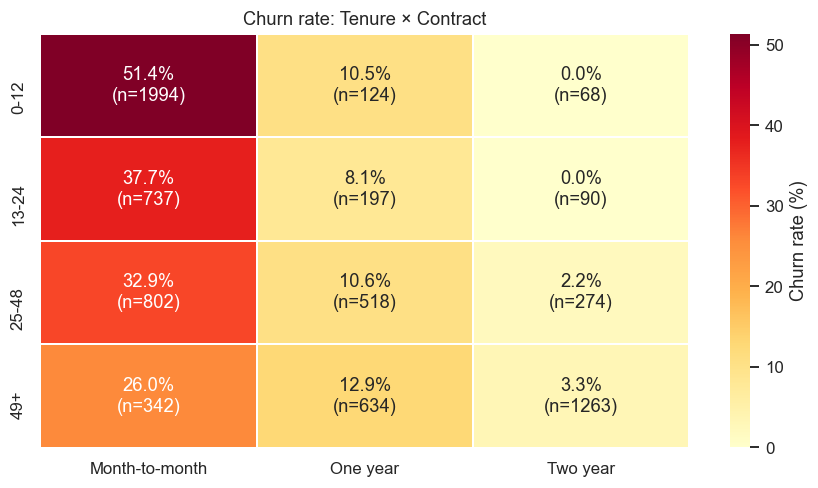

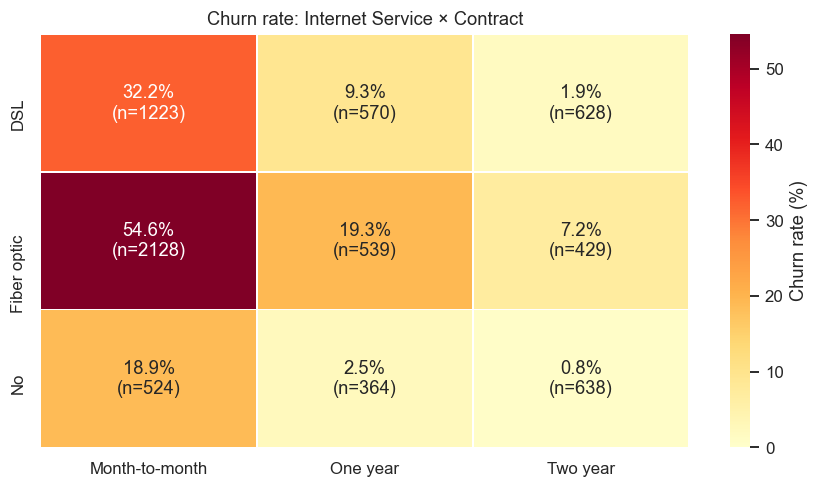

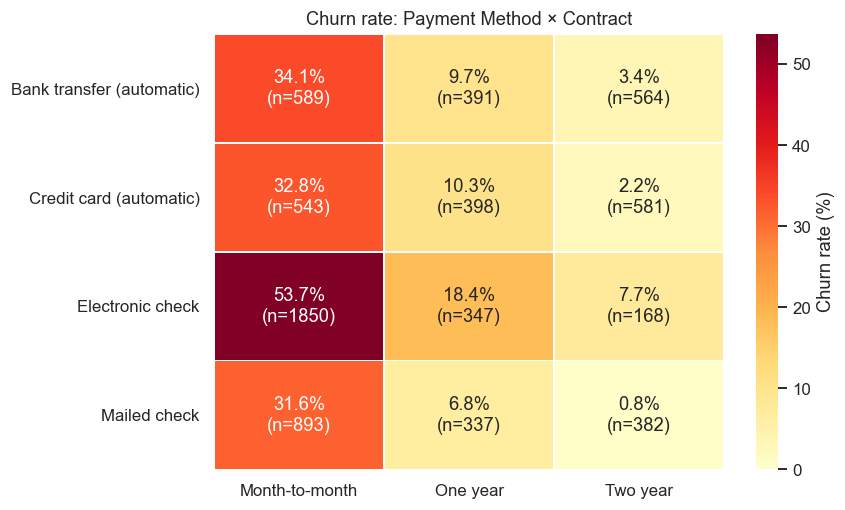

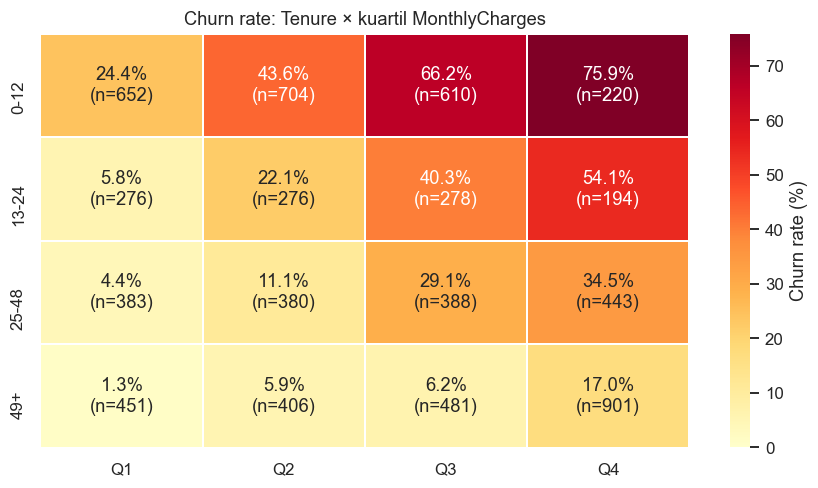

In [21]:
def churn_heatmap(row, col, title, fname, min_n=30, figsize=(8, 4.6)):
    g = df.groupby([row, col], observed=True)["ChurnBinary"].agg(["mean", "size"]).reset_index()
    rate = g.pivot(index=row, columns=col, values="mean") * 100
    cnt = g.pivot(index=row, columns=col, values="size")
    annot = rate.round(1).astype(str) + "%\n(n=" + cnt.fillna(0).astype(int).astype(str) + ")"
    annot = annot.where(cnt >= min_n, "–")
    plt.figure(figsize=figsize)
    sns.heatmap(rate.where(cnt >= min_n), annot=annot, fmt="", cmap="YlOrRd", vmin=0,
                linewidths=.5, cbar_kws={"label": "Churn rate (%)"})
    plt.title(title); plt.xlabel(""); plt.ylabel("")
    plt.tight_layout(); save_fig(fname); plt.show()
    return rate

_ = churn_heatmap("TenureGroup", "Contract", "Churn rate: Tenure × Contract", "eda_heatmap_tenure_contract")
_ = churn_heatmap("InternetService", "Contract", "Churn rate: Internet Service × Contract", "eda_heatmap_internet_contract")
_ = churn_heatmap("PaymentMethod", "Contract", "Churn rate: Payment Method × Contract", "eda_heatmap_payment_contract", figsize=(8, 4.8))
_ = churn_heatmap("TenureGroup", "MonthlyChargeGroup", "Churn rate: Tenure × kuartil MonthlyCharges", "eda_heatmap_tenure_charge")

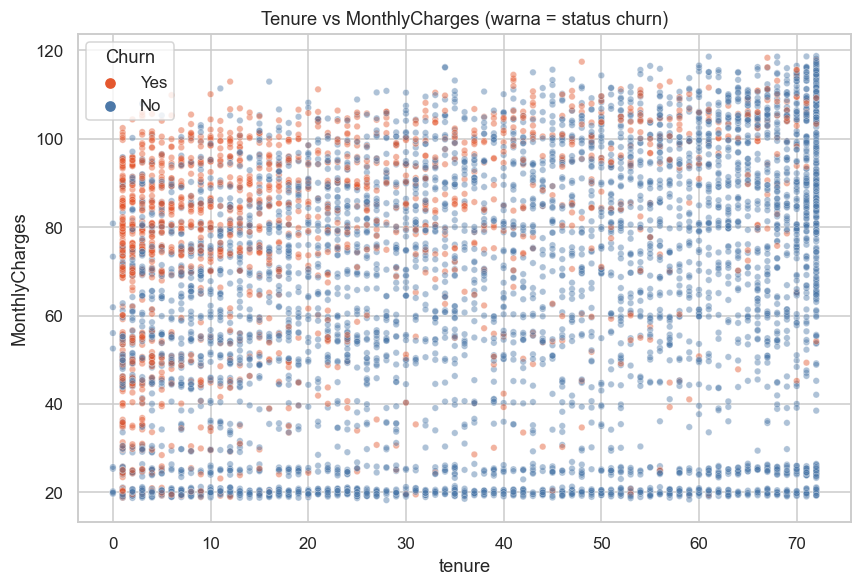

In [22]:
# Tenure x MonthlyCharges, warna = churn
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df.sample(frac=1, random_state=RANDOM_STATE), x="tenure", y="MonthlyCharges", hue="Churn",
                palette=PAL, alpha=.45, s=18, ax=ax)
ax.set_title("Tenure vs MonthlyCharges (warna = status churn)")
plt.tight_layout(); save_fig("eda_scatter_tenure_monthly"); plt.show()

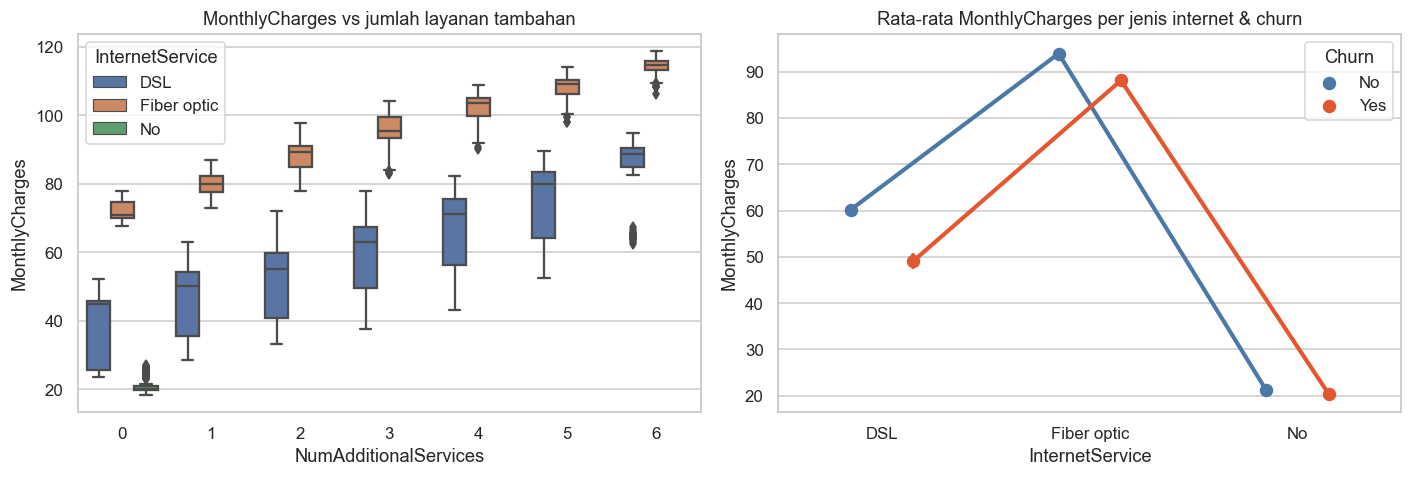

Spearman NumAdditionalServices vs MonthlyCharges: rho = 0.744, p = 0.00e+00


In [23]:
# Jumlah layanan tambahan vs MonthlyCharges (dipisah per jenis internet)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="NumAdditionalServices", y="MonthlyCharges", hue="InternetService", ax=axes[0])
axes[0].set_title("MonthlyCharges vs jumlah layanan tambahan")
sns.pointplot(data=df, x="InternetService", y="MonthlyCharges", hue="Churn", palette=PAL, dodge=.3,
              errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("Rata-rata MonthlyCharges per jenis internet & churn")
plt.tight_layout(); save_fig("eda_services_vs_charges"); plt.show()

r, p = stats.spearmanr(df["NumAdditionalServices"], df["MonthlyCharges"])
print(f"Spearman NumAdditionalServices vs MonthlyCharges: rho = {r:.3f}, p = {p:.2e}")

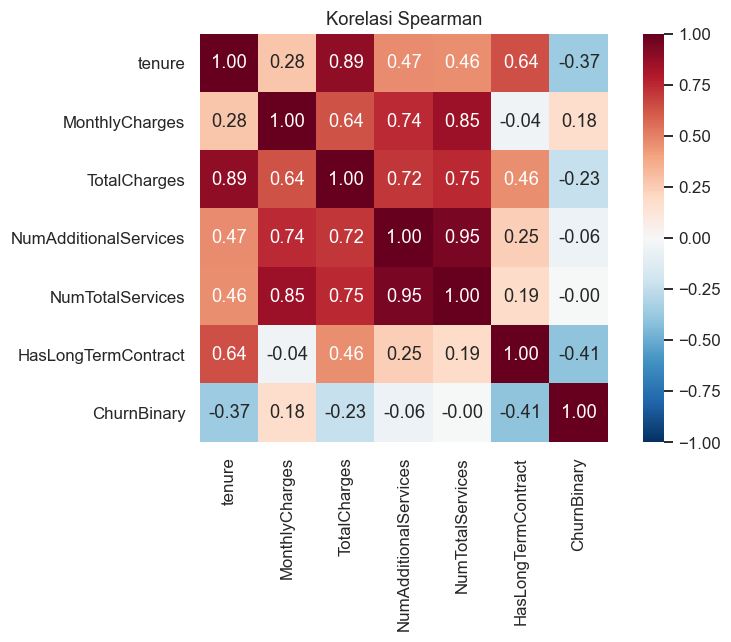

Korelasi tenure–TotalCharges  : 0.89
Korelasi MonthlyCharges–TotalCharges: 0.638
-> TotalCharges sangat terkait dengan tenure (akumulasi). Jangan diinterpretasi sebagai 'mahal/murah'.


In [24]:
# Korelasi Spearman antar variabel numerik (Pearson tidak dipakai: distribusi miring / ordinal)
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "NumAdditionalServices",
             "NumTotalServices", "HasLongTermContract", "ChurnBinary"]
corr = df[corr_cols].corr(method="spearman")
save_tab(corr, "eda_spearman_correlation")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Korelasi Spearman"); plt.tight_layout(); save_fig("eda_correlation_heatmap"); plt.show()

print("Korelasi tenure–TotalCharges  :", round(corr.loc["tenure", "TotalCharges"], 3))
print("Korelasi MonthlyCharges–TotalCharges:", round(corr.loc["MonthlyCharges", "TotalCharges"], 3))
print("-> TotalCharges sangat terkait dengan tenure (akumulasi). Jangan diinterpretasi sebagai 'mahal/murah'.")

---
## 4.5 Statistical Analysis dan Hypothesis Testing

Tingkat signifikansi **α = 0,05**. Karena banyak uji dilakukan sekaligus, p-value dikoreksi dengan **Benjamini–Hochberg (FDR)**.

| Kode | H0 | Uji |
|---|---|---|
| H1 | Distribusi churn tidak berbeda antar jenis kontrak | Chi-square + Cramér's V |
| H2 | Tenure churn = non-churn | Mann–Whitney U + Cliff's delta |
| H3 | MonthlyCharges churn = non-churn | Mann–Whitney U + Cliff's delta |
| H4 | Metode pembayaran tidak berhubungan dengan churn | Chi-square + Cramér's V |
| H5 | Jenis layanan internet tidak berhubungan dengan churn | Chi-square + Cramér's V |

### A. Chi-Square Test of Independence + Cramér's V

In [25]:
def cramers_v(ct):
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

def v_label(v):      # ambang Cohen (untuk tabel dengan df = 1); indikatif saja
    return "diabaikan" if v < .1 else "kecil" if v < .3 else "sedang" if v < .5 else "besar"

chi_vars = cat_cols + ["TenureGroup", "MonthlyChargeGroup"]
rows = []
for c in chi_vars:
    ct = pd.crosstab(df[c], df["Churn"])
    chi2, p, dof, exp = chi2_contingency(ct, correction=False)
    v = cramers_v(ct)
    rows.append({"Variabel": c, "Uji": "Chi-square", "Statistik": chi2, "df": dof, "p_value": p,
                 "Effect size": v, "Jenis effect size": "Cramér's V", "Besar efek": v_label(v),
                 "Min expected count": exp.min()})
chi_tbl = pd.DataFrame(rows)
print("Peringatan: sel dengan expected count < 5 ->", (chi_tbl["Min expected count"] < 5).sum(), "variabel")
chi_tbl.sort_values("Effect size", ascending=False).reset_index(drop=True)

Peringatan: sel dengan expected count < 5 -> 0 variabel


,Variabel,Uji,Statistik,df,p_value,Effect size,Jenis effect size,Besar efek,Min expected count
0,Contract,Chi-square,"1,184.5966",2,0.0000,0.4101,Cramér's V,sedang,390.8898
1,TenureGroup,Chi-square,856.1002,3,0.0000,0.3486,Cramér's V,sedang,271.7387
2,OnlineSecurity,Chi-square,849.9990,2,0.0000,0.3474,Cramér's V,sedang,404.9544
3,TechSupport,Chi-square,828.1971,2,0.0000,0.3429,Cramér's V,sedang,404.9544
4,InternetService,Chi-square,732.3096,2,0.0000,0.3225,Cramér's V,sedang,404.9544
5,PaymentMethod,Chi-square,648.1423,3,0.0000,0.3034,Cramér's V,sedang,403.8929
6,OnlineBackup,Chi-square,601.8128,2,0.0000,0.2923,Cramér's V,kecil,404.9544
7,DeviceProtection,Chi-square,558.4194,2,0.0000,0.2816,Cramér's V,kecil,404.9544
8,StreamingMovies,Chi-square,375.6615,2,0.0000,0.2310,Cramér's V,kecil,404.9544
9,StreamingTV,Chi-square,374.2039,2,0.0000,0.2305,Cramér's V,kecil,404.9544


### B. Variabel Numerik: Churn vs Non-churn (Mann–Whitney U + Cliff's delta)

Mann–Whitney dipilih sebagai uji utama karena distribusi `tenure`, `MonthlyCharges`, `TotalCharges` tidak simetris/normal. Welch t-test dilaporkan hanya sebagai pembanding.

Cliff's delta = P(X_churn > X_non) − P(X_churn < X_non). Positif → pelanggan churn cenderung bernilai lebih besar. Ambang: |δ| < 0,147 diabaikan; < 0,33 kecil; < 0,474 sedang; selain itu besar.

In [26]:
def cliffs_delta_label(d):
    d = abs(d)
    return "diabaikan" if d < .147 else "kecil" if d < .33 else "sedang" if d < .474 else "besar"

num_test_vars = num_cols + ["NumAdditionalServices", "NumTotalServices"]
rows = []
for c in num_test_vars:
    x = df.loc[df["Churn"] == "Yes", c]
    y = df.loc[df["Churn"] == "No", c]
    u, p = mannwhitneyu(x, y, alternative="two-sided")
    delta = 2 * u / (len(x) * len(y)) - 1
    t_p = stats.ttest_ind(x, y, equal_var=False).pvalue
    rows.append({
        "Variabel": c, "Uji": "Mann-Whitney U", "Statistik": u, "p_value": p,
        "Effect size": delta, "Jenis effect size": "Cliff's delta", "Besar efek": cliffs_delta_label(delta),
        "Median churn": x.median(), "IQR churn": x.quantile(.75) - x.quantile(.25),
        "Median non-churn": y.median(), "IQR non-churn": y.quantile(.75) - y.quantile(.25),
        "Mean churn": x.mean(), "Mean non-churn": y.mean(), "p Welch t-test (pembanding)": t_p,
    })
mw_tbl = pd.DataFrame(rows)
mw_tbl

,Variabel,Uji,Statistik,p_value,Effect size,Jenis effect size,Besar efek,Median churn,IQR churn,Median non-churn,IQR non-churn,Mean churn,Mean non-churn,p Welch t-test (pembanding)
0,tenure,Mann-Whitney U,"2,515,538.0000",0.0000,-0.4797,Cliff's delta,besar,10.0000,27.0000,38.0000,46.0000,17.9791,37.5700,0.0000
1,MonthlyCharges,Mann-Whitney U,"6,003,125.5000",0.0000,0.2416,Cliff's delta,kecil,79.6500,38.0500,64.4250,63.3000,74.4413,61.2651,0.0000
2,TotalCharges,Mann-Whitney U,"3,381,224.0000",0.0000,-0.3007,Cliff's delta,kecil,703.5500,"2,196.8000","1,679.5250","3,689.9500","1,531.7961","2,549.9114",0.0000
3,NumAdditionalServices,Mann-Whitney U,"4,463,946.5000",0.0000,-0.0768,Cliff's delta,diabaikan,2.0000,3.0000,2.0000,4.0000,1.7683,2.1353,0.0000
4,NumTotalServices,Mann-Whitney U,"4,804,660.0000",0.6836,-0.0063,Cliff's delta,diabaikan,4.0000,2.0000,4.0000,4.0000,4.0717,4.1732,0.0631


In [27]:
# Ringkasan seluruh uji + koreksi Benjamini-Hochberg
summary = pd.concat([
    chi_tbl[["Variabel", "Uji", "Statistik", "p_value", "Effect size", "Jenis effect size", "Besar efek"]],
    mw_tbl[["Variabel", "Uji", "Statistik", "p_value", "Effect size", "Jenis effect size", "Besar efek"]],
], ignore_index=True)
reject, p_adj, _, _ = multipletests(summary["p_value"], alpha=ALPHA, method="fdr_bh")
summary["p_adj_BH"] = p_adj
summary["Signifikan (BH)"] = np.where(reject, "Ya", "Tidak")
summary = summary.sort_values("p_adj_BH").reset_index(drop=True)
save_tab(summary, "stat_test_summary", index=False)
save_tab(mw_tbl, "stat_mannwhitney_detail", index=False)
save_tab(chi_tbl, "stat_chisquare_detail", index=False)

fmt = summary.copy()
fmt["p_value"] = fmt["p_value"].map(lambda v: f"{v:.2e}")
fmt["p_adj_BH"] = fmt["p_adj_BH"].map(lambda v: f"{v:.2e}")
fmt

,Variabel,Uji,Statistik,p_value,Effect size,Jenis effect size,Besar efek,p_adj_BH,Signifikan (BH)
0,Contract,Chi-square,"1,184.5966",5.86e-258,0.4101,Cramér's V,sedang,1.35e-256,Ya
1,tenure,Mann-Whitney U,"2,515,538.0000",2.42e-208,-0.4797,Cliff's delta,besar,2.78e-207,Ya
2,TenureGroup,Chi-square,856.1002,2.94e-185,0.3486,Cramér's V,sedang,1.69e-184,Ya
3,OnlineSecurity,Chi-square,849.9990,2.66e-185,0.3474,Cramér's V,sedang,1.69e-184,Ya
4,TechSupport,Chi-square,828.1971,1.44e-180,0.3429,Cramér's V,sedang,6.64e-180,Ya
5,InternetService,Chi-square,732.3096,9.57e-160,0.3225,Cramér's V,sedang,3.67e-159,Ya
6,PaymentMethod,Chi-square,648.1423,3.68e-140,0.3034,Cramér's V,sedang,1.21e-139,Ya
7,OnlineBackup,Chi-square,601.8128,2.08e-131,0.2923,Cramér's V,kecil,5.98e-131,Ya
8,DeviceProtection,Chi-square,558.4194,5.51e-122,0.2816,Cramér's V,kecil,1.41e-121,Ya
9,TotalCharges,Mann-Whitney U,"3,381,224.0000",5.69e-83,-0.3007,Cliff's delta,kecil,1.31e-82,Ya


In [28]:
# Jawaban untuk hipotesis H1-H5
hyp = {"H1": "Contract", "H2": "tenure", "H3": "MonthlyCharges", "H4": "PaymentMethod", "H5": "InternetService"}
h_rows = []
for k, v in hyp.items():
    r = summary[summary["Variabel"] == v].iloc[0]
    sig = r["p_adj_BH"] < ALPHA
    h_rows.append({"Hipotesis": k, "Variabel": v, "Uji": r["Uji"], "p (BH)": f"{r['p_adj_BH']:.2e}",
                   "Effect size": f"{r['Jenis effect size']} = {r['Effect size']:.3f} ({r['Besar efek']})",
                   "Keputusan": "Tolak H0" if sig else "Gagal menolak H0"})
hyp_tbl = pd.DataFrame(h_rows)
save_tab(hyp_tbl, "stat_hypothesis_decisions", index=False)
hyp_tbl

,Hipotesis,Variabel,Uji,p (BH),Effect size,Keputusan
0,H1,Contract,Chi-square,1.35e-256,Cramér's V = 0.410 (sedang),Tolak H0
1,H2,tenure,Mann-Whitney U,2.78e-207,Cliff's delta = -0.480 (besar),Tolak H0
2,H3,MonthlyCharges,Mann-Whitney U,5.08e-54,Cliff's delta = 0.242 (kecil),Tolak H0
3,H4,PaymentMethod,Chi-square,1.21e-139,Cramér's V = 0.303 (sedang),Tolak H0
4,H5,InternetService,Chi-square,3.67e-159,Cramér's V = 0.322 (sedang),Tolak H0


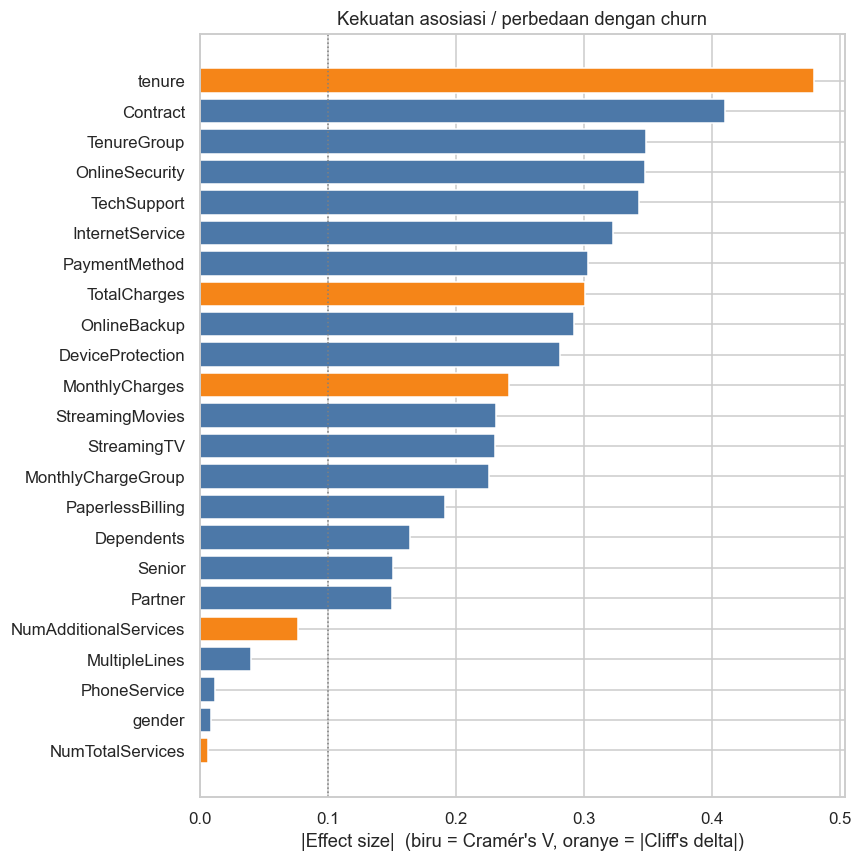

In [29]:
# Visual: effect size seluruh variabel (membantu membedakan "signifikan" vs "kuat")
plot_df = summary.copy()
plot_df["abs_es"] = plot_df["Effect size"].abs()
plot_df = plot_df.sort_values("abs_es")
colors = plot_df["Jenis effect size"].map({"Cramér's V": "#4C78A8", "Cliff's delta": "#F58518"})
plt.figure(figsize=(8, 8))
plt.barh(plot_df["Variabel"], plot_df["abs_es"], color=colors)
plt.axvline(.1, color="grey", ls=":", lw=1)
plt.xlabel("|Effect size|  (biru = Cramér's V, oranye = |Cliff's delta|)")
plt.title("Kekuatan asosiasi / perbedaan dengan churn")
plt.tight_layout(); save_fig("stat_effect_size_ranking"); plt.show()

### C. Regresi Logistik Multivariabel (Inferensial) + Odds Ratio

Tujuan: melihat apakah suatu faktor **masih berasosiasi dengan churn setelah memperhitungkan faktor lain**.
Skala variabel: `tenure` per **12 bulan**, `MonthlyCharges` per **10 USD** agar OR mudah dibaca.
Kategori referensi: Contract = Month-to-month, InternetService = DSL, PaymentMethod = Bank transfer (automatic).
OR > 1 → odds churn lebih tinggi dibanding referensi; OR < 1 → lebih rendah.

In [30]:
dfm = df.copy()
dfm["tenure_12m"] = dfm["tenure"] / 12
dfm["MonthlyCharges_10"] = dfm["MonthlyCharges"] / 10
dfm["Contract"] = dfm["Contract"].astype(str)

f1 = ("ChurnBinary ~ tenure_12m + MonthlyCharges_10"
      " + C(Contract, Treatment('Month-to-month'))"
      " + C(InternetService, Treatment('DSL'))"
      " + C(PaymentMethod, Treatment('Bank transfer (automatic)'))")

f2 = (f1 + " + NumAdditionalServices + C(PaperlessBilling, Treatment('No'))"
      " + C(Senior, Treatment('No')) + C(Partner, Treatment('No')) + C(Dependents, Treatment('No'))")

def clean_term(s):
    s = re.sub(r"C\((\w+), Treatment\('([^']*)'\)\)\[T\.([^\]]*)\]", r"\1: \3 (vs \2)", s)
    return re.sub(r"C\((\w+), Treatment\('([^']*)'\)\)", r"\1", s)

def or_table(res):
    ci = np.exp(res.conf_int())
    t = pd.DataFrame({"OR": np.exp(res.params), "CI95_low": ci[0], "CI95_high": ci[1], "p_value": res.pvalues})
    t.index = [clean_term(i) for i in t.index]
    return t.drop(index="Intercept")

m1 = smf.logit(f1, data=dfm).fit(disp=0)
m2 = smf.logit(f2, data=dfm).fit(disp=0)

or1, or2 = or_table(m1), or_table(m2)
save_tab(or1, "stat_logit_model1_or"); save_tab(or2, "stat_logit_model2_or")

print(f"Model 1 (sesuai rencana): n={int(m1.nobs)}, pseudo-R2 McFadden={m1.prsquared:.3f}, AIC={m1.aic:.1f}, LLR p={m1.llr_pvalue:.2e}")
print(f"Model 2 (diperluas)     : n={int(m2.nobs)}, pseudo-R2 McFadden={m2.prsquared:.3f}, AIC={m2.aic:.1f}, LLR p={m2.llr_pvalue:.2e}")
print(f"Konvergen: {m1.mle_retvals['converged']} / {m2.mle_retvals['converged']}")
print("\n=== Model 1: odds ratio ===")
or1

Model 1 (sesuai rencana): n=7043, pseudo-R2 McFadden=0.263, AIC=6030.4, LLR p=0.00e+00
Model 2 (diperluas)     : n=7043, pseudo-R2 McFadden=0.269, AIC=5986.2, LLR p=0.00e+00
Konvergen: True / True

=== Model 1: odds ratio ===


,OR,CI95_low,CI95_high,p_value
Contract: One year (vs Month-to-month),0.4486,0.3661,0.5497,0.0000
Contract: Two year (vs Month-to-month),0.1993,0.1428,0.2783,0.0000
InternetService: Fiber optic (vs DSL),2.6103,2.0318,3.3535,0.0000
InternetService: No (vs DSL),0.4477,0.3327,0.6024,0.0000
PaymentMethod: Credit card (automatic) (vs Bank transfer (automatic)),0.9356,0.7511,1.1655,0.5527
PaymentMethod: Electronic check (vs Bank transfer (automatic)),1.5621,1.3033,1.8723,0.0000
PaymentMethod: Mailed check (vs Bank transfer (automatic)),0.9323,0.7495,1.1597,0.5293
tenure_12m,0.6868,0.6535,0.7217,0.0000
MonthlyCharges_10,1.0382,0.9787,1.1012,0.2131


In [31]:
print("=== Model 2 (diperluas): odds ratio ===")
or2

=== Model 2 (diperluas): odds ratio ===


,OR,CI95_low,CI95_high,p_value
Contract: One year (vs Month-to-month),0.4888,0.3976,0.6009,0.0000
Contract: Two year (vs Month-to-month),0.2291,0.1632,0.3215,0.0000
InternetService: Fiber optic (vs DSL),2.2288,1.5463,3.2124,0.0000
InternetService: No (vs DSL),0.4987,0.3650,0.6814,0.0000
PaymentMethod: Credit card (automatic) (vs Bank transfer (automatic)),0.9189,0.7368,1.1460,0.4528
PaymentMethod: Electronic check (vs Bank transfer (automatic)),1.4929,1.2441,1.7914,0.0000
PaymentMethod: Mailed check (vs Bank transfer (automatic)),0.9608,0.7713,1.1969,0.7212
PaperlessBilling: Yes (vs No),1.4881,1.2895,1.7173,0.0000
Senior: Yes (vs No),1.3330,1.1315,1.5704,0.0006
Partner: Yes (vs No),1.0115,0.8702,1.1758,0.8812


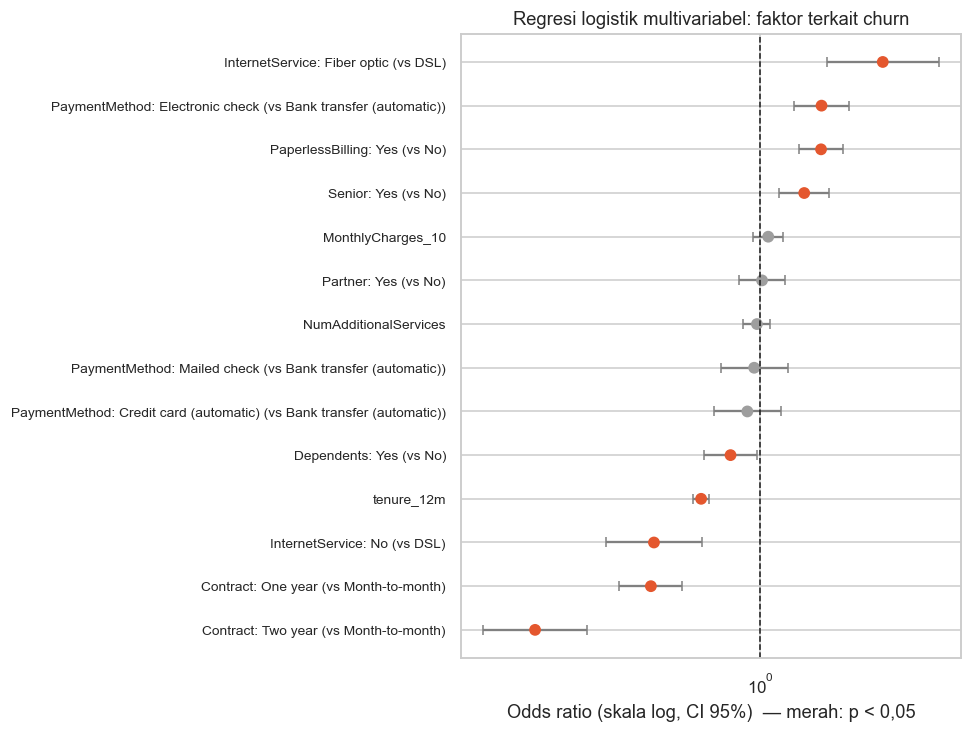

In [32]:
# Forest plot odds ratio (Model 2)
plot = or2.sort_values("OR")
fig, ax = plt.subplots(figsize=(9, 0.38 * len(plot) + 1.5))
sig = plot["p_value"] < ALPHA
ax.errorbar(plot["OR"], range(len(plot)),
            xerr=[plot["OR"] - plot["CI95_low"], plot["CI95_high"] - plot["OR"]],
            fmt="none", ecolor="grey", capsize=3, zorder=1)
ax.scatter(plot["OR"], range(len(plot)), c=np.where(sig, "#E4572E", "#9e9e9e"), s=45, zorder=2)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index, fontsize=9)
ax.set_xlabel("Odds ratio (skala log, CI 95%)  — merah: p < 0,05")
ax.set_title("Regresi logistik multivariabel: faktor terkait churn")
plt.tight_layout(); save_fig("stat_logit_forest_plot"); plt.show()

In [33]:
# Pemeriksaan multikolinearitas (VIF) pada Model 2
y_, X_ = dmatrices(f2, dfm, return_type="dataframe")
vif = pd.DataFrame({"Variabel": [clean_term(c) for c in X_.columns],
                    "VIF": [variance_inflation_factor(X_.values, i) for i in range(X_.shape[1])]})
vif = vif[vif["Variabel"] != "Intercept"].sort_values("VIF", ascending=False).reset_index(drop=True)
save_tab(vif, "stat_logit_vif", index=False)
display(vif)

# Mengapa TotalCharges TIDAK dimasukkan ke model inferensial:
vx = dfm[["tenure", "MonthlyCharges", "TotalCharges"]].assign(const=1.0)
vif_tot = pd.Series({c: variance_inflation_factor(vx.values, i) for i, c in enumerate(vx.columns) if c != "const"})
print("\nVIF jika tenure + MonthlyCharges + TotalCharges dimasukkan bersamaan:")
print(vif_tot.round(2).to_string())

,Variabel,VIF
0,MonthlyCharges_10,20.7262
1,InternetService: Fiber optic (vs DSL),7.9685
2,NumAdditionalServices,6.3764
3,InternetService: No (vs DSL),3.5820
4,tenure_12m,2.5956
5,Contract: Two year (vs Month-to-month),2.5638
6,PaymentMethod: Electronic check (vs Bank trans...,1.9494
7,PaymentMethod: Mailed check (vs Bank transfer ...,1.8370
8,Contract: One year (vs Month-to-month),1.6073
9,PaymentMethod: Credit card (automatic) (vs Ban...,1.5596



VIF jika tenure + MonthlyCharges + TotalCharges dimasukkan bersamaan:
tenure           5.8400
MonthlyCharges   3.2200
TotalCharges     9.5100


---
## 4.6 Customer Segmentation dengan K-Means

Fitur clustering (dari Orang 1): `tenure`, `MonthlyCharges`, `TotalCharges`, `NumAdditionalServices`, `NumTotalServices`.
**`Churn` tidak dipakai** untuk membentuk cluster; ia hanya dipakai setelahnya untuk mengevaluasi tiap segmen.
Standardisasi dengan `StandardScaler` agar skala (mis. `TotalCharges`) tidak mendominasi jarak Euclidean.

Matriks fitur: (7043, 5)


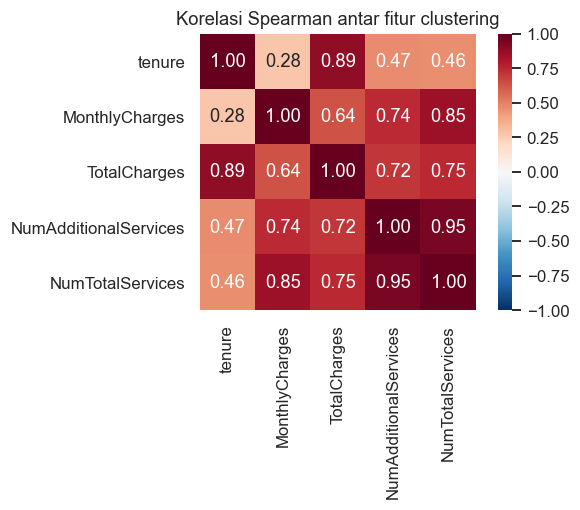

In [34]:
cf = pd.read_csv(PROCESSED / "telco_clustering_features.csv")
cluster_features = ["tenure", "MonthlyCharges", "TotalCharges", "NumAdditionalServices", "NumTotalServices"]
assert list(cf.columns) == ["customerID"] + cluster_features
assert "Churn" not in cf.columns and "ChurnBinary" not in cf.columns
assert cf["customerID"].is_unique and set(cf["customerID"]) == set(df["customerID"])

# Gabungkan label churn & atribut lain HANYA untuk profiling (bukan untuk clustering)
cdf = cf.merge(df[["customerID", "Churn", "ChurnBinary", "TenureGroup", "Contract", "InternetService",
                   "PaymentMethod", "Senior"]], on="customerID", how="left", validate="one_to_one")

X = StandardScaler().fit_transform(cdf[cluster_features])
print("Matriks fitur:", X.shape)

# Korelasi antar fitur clustering (TotalCharges ~ tenure x MonthlyCharges -> beban 'ukuran akun' lebih besar)
cf_corr = cdf[cluster_features].corr(method="spearman")
plt.figure(figsize=(6, 4.8))
sns.heatmap(cf_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Korelasi Spearman antar fitur clustering"); plt.tight_layout()
save_fig("cluster_feature_correlation"); plt.show()

### A. Menentukan jumlah cluster (K = 2 … 8)

In [35]:
K_RANGE = range(2, 9)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    rows.append({"K": k, "WCSS": km.inertia_,
                 "Silhouette": silhouette_score(X, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
                 "Ukuran cluster terkecil (%)": np.bincount(km.labels_).min() / len(X) * 100})
k_tbl = pd.DataFrame(rows).set_index("K")
k_tbl["Penurunan WCSS (%)"] = -k_tbl["WCSS"].pct_change() * 100
save_tab(k_tbl, "cluster_k_selection")
k_tbl

  File "C:\Users\melin\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\melin\anaconda3\lib\subprocess.py", line 489, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\melin\anaconda3\lib\subprocess.py", line 854, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\melin\anaconda3\lib\subprocess.py", line 1307, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,WCSS,Silhouette,Davies-Bouldin,Calinski-Harabasz,Ukuran cluster terkecil (%),Penurunan WCSS (%)
K,,,,,,
2,"15,834.7960",0.4592,0.8409,"8,617.4976",40.1533,nan
3,"10,755.1651",0.4024,0.9246,"8,005.3758",29.1069,32.0789
4,"8,567.4578",0.3588,1.0190,"7,297.9983",17.7197,20.3410
5,"6,917.9448",0.3543,0.9655,"7,197.0366",12.0687,19.2532
6,"5,681.4260",0.3720,0.9441,"7,316.0604",11.1032,17.8741
7,"5,014.8021",0.3642,0.9921,"7,062.0619",9.9247,11.7334
8,"4,559.6126",0.3593,0.9992,"6,756.8915",8.5191,9.0769


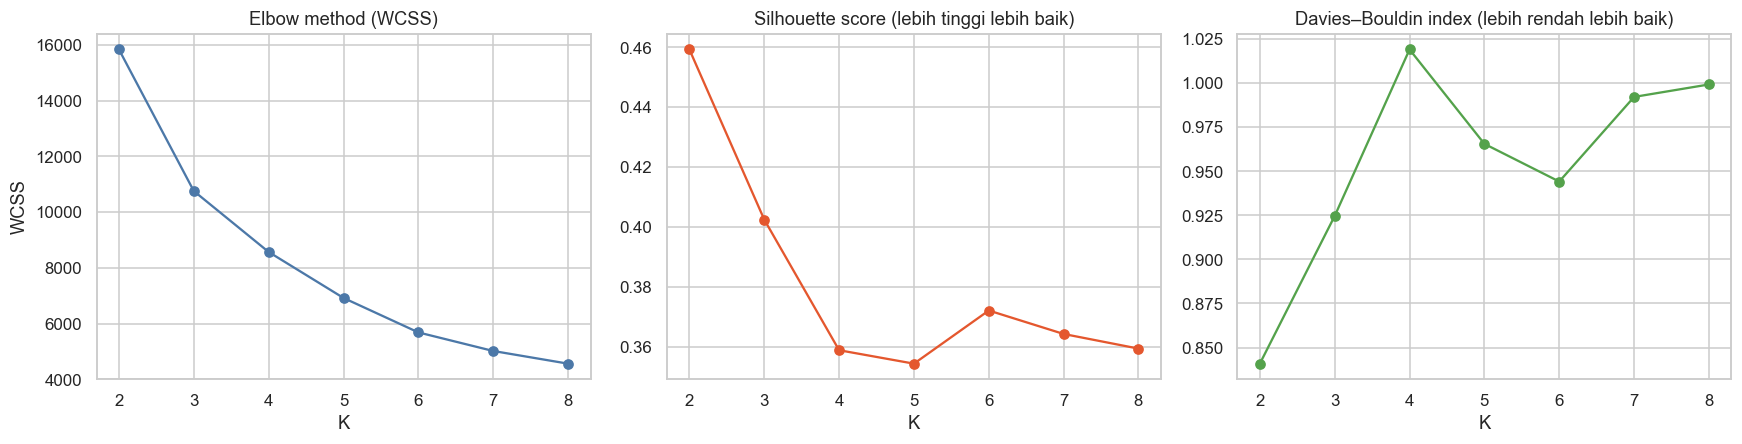

K terbaik menurut Silhouette: 2 | menurut Davies-Bouldin: 2


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(k_tbl.index, k_tbl["WCSS"], "o-", color="#4C78A8")
axes[0].set_title("Elbow method (WCSS)"); axes[0].set_xlabel("K"); axes[0].set_ylabel("WCSS")
axes[1].plot(k_tbl.index, k_tbl["Silhouette"], "o-", color="#E4572E")
axes[1].set_title("Silhouette score (lebih tinggi lebih baik)"); axes[1].set_xlabel("K")
axes[2].plot(k_tbl.index, k_tbl["Davies-Bouldin"], "o-", color="#54A24B")
axes[2].set_title("Davies–Bouldin index (lebih rendah lebih baik)"); axes[2].set_xlabel("K")
for a in axes: a.set_xticks(list(K_RANGE))
plt.tight_layout(); save_fig("cluster_elbow_silhouette_db"); plt.show()

best_sil = int(k_tbl["Silhouette"].idxmax()); best_db = int(k_tbl["Davies-Bouldin"].idxmin())
print(f"K terbaik menurut Silhouette: {best_sil} | menurut Davies-Bouldin: {best_db}")

**Memilih K.** Silhouette sering paling tinggi pada K = 2 (hanya memisahkan "kecil vs besar"), padahal tujuan penelitian adalah segmentasi
yang bermakna secara bisnis. Karena itu K dipilih dengan mempertimbangkan **(1)** Silhouette dan Davies–Bouldin,
**(2)** titik siku WCSS, **(3)** ukuran cluster terkecil tidak terlalu kecil, dan **(4)** interpretabilitas profil.
Ubah `K_FINAL` di bawah setelah memeriksa tabel & grafik di atas; alasan pemilihan harus ditulis di laporan.

In [37]:
K_FINAL = 4     # <- ubah sesuai pertimbangan di atas

km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE).fit(X)

# Beri nomor cluster berurutan menurut rata-rata tenure (naik) supaya mudah dibaca & reprodusibel
order = cdf.assign(_c=km_final.labels_).groupby("_c")["tenure"].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
cdf["Cluster"] = pd.Series(km_final.labels_).map(remap).values
print("Silhouette K_FINAL:", round(silhouette_score(X, cdf["Cluster"]), 4),
      "| Davies-Bouldin:", round(davies_bouldin_score(X, cdf["Cluster"]), 4))
cdf["Cluster"].value_counts().sort_index().to_frame("Jumlah pelanggan").assign(
    Persen=lambda t: t["Jumlah pelanggan"] / len(cdf) * 100)

Silhouette K_FINAL: 0.3585 | Davies-Bouldin: 1.0203


,Jumlah pelanggan,Persen
0,2093,29.7174
1,2000,28.3970
2,1694,24.0523
3,1256,17.8333


In [38]:
# Uji stabilitas: ulangi K-Means dengan seed berbeda, bandingkan kemiripan partisi (ARI; 1 = identik)
ari = []
for s in range(10):
    lab = KMeans(n_clusters=K_FINAL, n_init=10, random_state=100 + s).fit_predict(X)
    ari.append(adjusted_rand_score(cdf["Cluster"], lab))
print(f"Stabilitas antar seed (ARI): mean={np.mean(ari):.3f}, min={np.min(ari):.3f}")

# Robustness: tanpa TotalCharges (karena terkait erat dengan tenure x MonthlyCharges)
feat_noT = [f for f in cluster_features if f != "TotalCharges"]
X_noT = StandardScaler().fit_transform(cdf[feat_noT])
lab_noT = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit_predict(X_noT)
print(f"ARI cluster dengan vs tanpa TotalCharges: {adjusted_rand_score(cdf['Cluster'], lab_noT):.3f}")

# Robustness: K±1
for k in [K_FINAL - 1, K_FINAL + 1]:
    lab = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    print(f"ARI K_FINAL vs K={k}: {adjusted_rand_score(cdf['Cluster'], lab):.3f}")

Stabilitas antar seed (ARI): mean=0.984, min=0.970
ARI cluster dengan vs tanpa TotalCharges: 0.410
ARI K_FINAL vs K=3: 0.660
ARI K_FINAL vs K=5: 0.600


### B. Profil cluster dan churn rate per cluster

In [39]:
# Profil numerik
prof = cdf.groupby("Cluster")[cluster_features].mean()
prof.insert(0, "Jumlah pelanggan", cdf["Cluster"].value_counts().sort_index())
prof.insert(1, "Persen", prof["Jumlah pelanggan"] / len(cdf) * 100)

# Profil kategorikal & churn
prof["% Month-to-month"] = cdf.groupby("Cluster")["Contract"].apply(lambda s: (s.astype(str) == "Month-to-month").mean() * 100)
prof["% Fiber optic"] = cdf.groupby("Cluster")["InternetService"].apply(lambda s: (s == "Fiber optic").mean() * 100)
prof["% Tanpa internet"] = cdf.groupby("Cluster")["InternetService"].apply(lambda s: (s == "No").mean() * 100)
prof["% Electronic check"] = cdf.groupby("Cluster")["PaymentMethod"].apply(lambda s: (s == "Electronic check").mean() * 100)
prof["% Senior"] = cdf.groupby("Cluster")["Senior"].apply(lambda s: (s == "Yes").mean() * 100)

g = cdf.groupby("Cluster")["ChurnBinary"].agg(["sum", "size", "mean"])
lo, hi = proportion_confint(g["sum"], g["size"], method="wilson")
prof["Churn rate (%)"] = g["mean"] * 100
prof["CI95 low"], prof["CI95 high"] = lo * 100, hi * 100
prof["Lift vs rata-rata"] = prof["Churn rate (%)"] / overall_churn

save_tab(prof, "cluster_profile")
prof.T

Cluster,0,1,2,3
Jumlah pelanggan,"2,093.0000","2,000.0000","1,694.0000","1,256.0000"
Persen,29.7174,28.3970,24.0523,17.8333
tenure,10.5585,27.1820,42.2432,63.6680
MonthlyCharges,71.7493,25.0783,78.5580,97.7003
TotalCharges,746.9877,657.6712,"3,183.4721","6,197.9134"
NumAdditionalServices,1.4749,0.1320,3.0714,4.6170
NumTotalServices,3.7621,1.4190,5.4368,7.3885
% Month-to-month,91.7344,46.6500,48.6423,15.7643
% Fiber optic,63.3540,0.4000,51.8300,70.3822
% Tanpa internet,0.0000,76.3000,0.0000,0.0000


In [40]:
# Draf label deskriptif otomatis (z-score rata-rata cluster terhadap populasi). HANYA draf: periksa & ubah manual.
z = (prof[cluster_features] - cdf[cluster_features].mean()) / cdf[cluster_features].std()

def level(v):
    return "tinggi" if v > .5 else "rendah" if v < -.5 else "sedang"

draft = {}
for c in z.index:
    draft[c] = (f"tenure {level(z.loc[c, 'tenure'])}, biaya {level(z.loc[c, 'MonthlyCharges'])}, "
                f"layanan {level(z.loc[c, 'NumTotalServices'])}")

# Setelah melihat profil, isi nama bisnis di sini, contoh: {0: "Pelanggan baru berbiaya rendah", ...}
CLUSTER_NAMES = {}

names = {c: CLUSTER_NAMES.get(c, draft[c]) for c in z.index}
cdf["ClusterName"] = cdf["Cluster"].map(names)
pd.DataFrame({"Cluster": list(names), "Label": list(names.values()),
              "Churn rate (%)": prof["Churn rate (%)"].values}).set_index("Cluster")

,Label,Churn rate (%)
Cluster,,
0,"tenure rendah, biaya sedang, layanan sedang",50.2628
1,"tenure sedang, biaya rendah, layanan rendah",13.9000
2,"tenure sedang, biaya sedang, layanan tinggi",21.7828
3,"tenure tinggi, biaya tinggi, layanan tinggi",13.5350


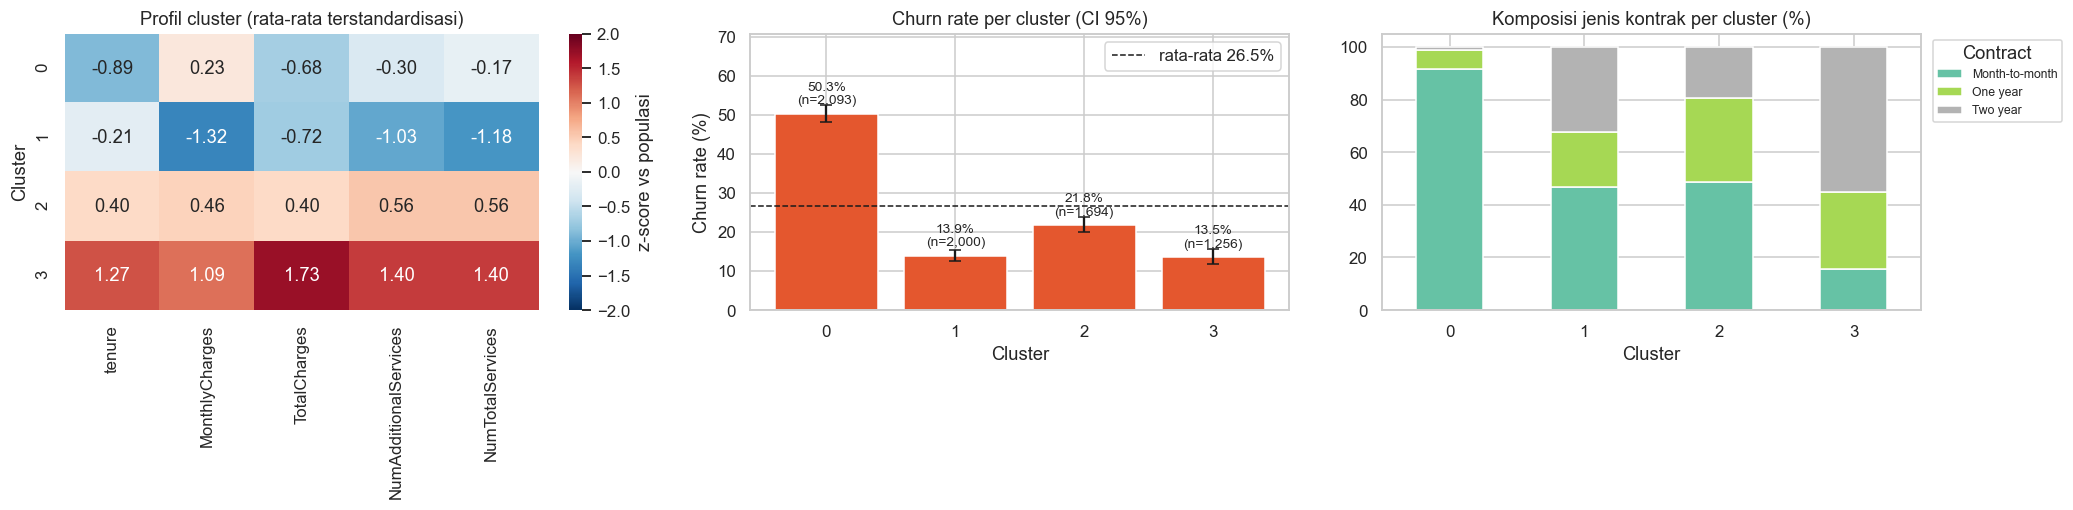

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1.1, 1, 1]})

# (1) heatmap z-score fitur per cluster
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, ax=axes[0],
            cbar_kws={"label": "z-score vs populasi"})
axes[0].set_title("Profil cluster (rata-rata terstandardisasi)")

# (2) churn rate per cluster + CI
axes[1].bar(prof.index.astype(str), prof["Churn rate (%)"], color="#E4572E",
            yerr=[prof["Churn rate (%)"] - prof["CI95 low"], prof["CI95 high"] - prof["Churn rate (%)"]], capsize=4)
axes[1].axhline(overall_churn, color="k", ls="--", lw=1, label=f"rata-rata {overall_churn:.1f}%")
for i, (v, n) in enumerate(zip(prof["Churn rate (%)"], prof["Jumlah pelanggan"])):
    axes[1].text(i, v + 2.5, f"{v:.1f}%\n(n={n:,})", ha="center", fontsize=9)
axes[1].set_title("Churn rate per cluster (CI 95%)"); axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Churn rate (%)")
axes[1].set_ylim(0, prof["CI95 high"].max() * 1.35); axes[1].legend()

# (3) komposisi kontrak per cluster
comp = pd.crosstab(cdf["Cluster"], cdf["Contract"], normalize="index") * 100
comp.plot.bar(stacked=True, ax=axes[2], rot=0, colormap="Set2")
axes[2].set_title("Komposisi jenis kontrak per cluster (%)"); axes[2].set_xlabel("Cluster"); axes[2].legend(title="Contract", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); save_fig("cluster_profile_churn_contract"); plt.show()

Varians dijelaskan PC1+PC2: 93.1%


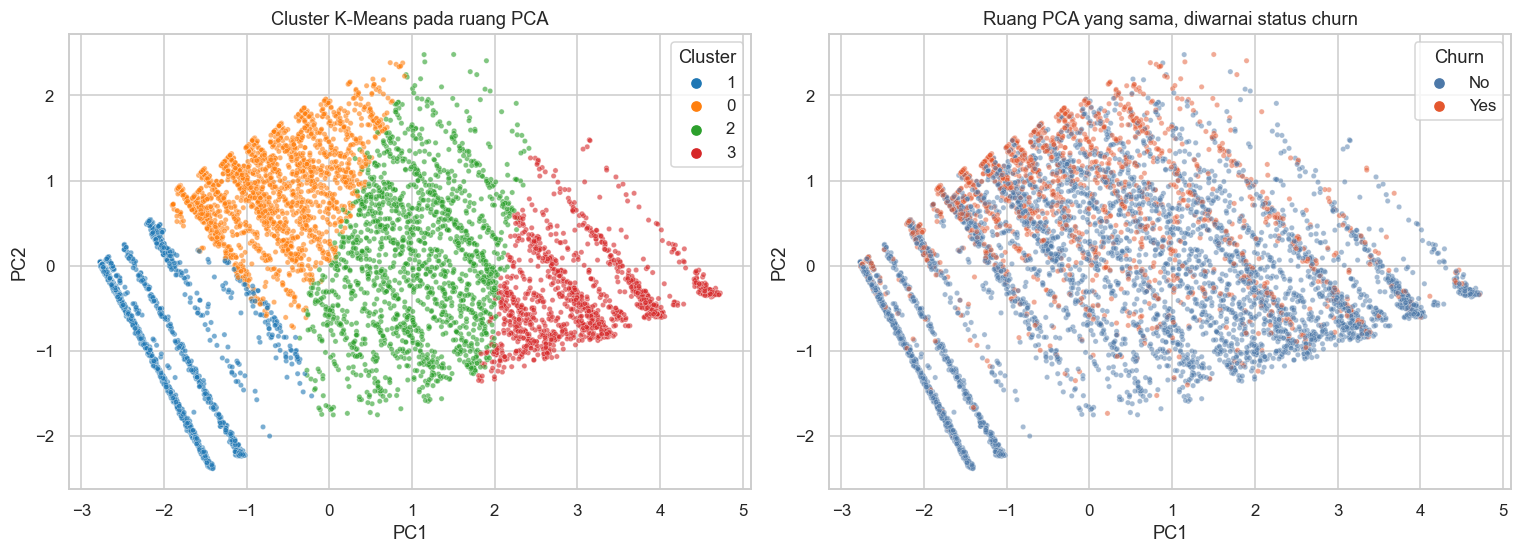

In [42]:
# Visualisasi 2D (PCA) — hanya alat bantu visual; clustering dilakukan pada 5 dimensi asli
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
print("Varians dijelaskan PC1+PC2:", f"{pca.explained_variance_ratio_.sum() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=cdf["Cluster"].astype(str), palette="tab10", s=12, alpha=.6, ax=axes[0])
axes[0].set_title("Cluster K-Means pada ruang PCA"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=cdf["Churn"], palette=PAL, s=12, alpha=.5, ax=axes[1])
axes[1].set_title("Ruang PCA yang sama, diwarnai status churn"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.tight_layout(); save_fig("cluster_pca_scatter"); plt.show()

Cluster vs Churn: chi2=896.7, df=3, p=4.51e-194, Cramér's V=0.357
Catatan: cluster tidak dibentuk dari churn, sehingga asosiasi ini bukan sesuatu yang 'dipaksakan' oleh desain.
Pembanding — Cramér's V Contract vs Churn: 0.410


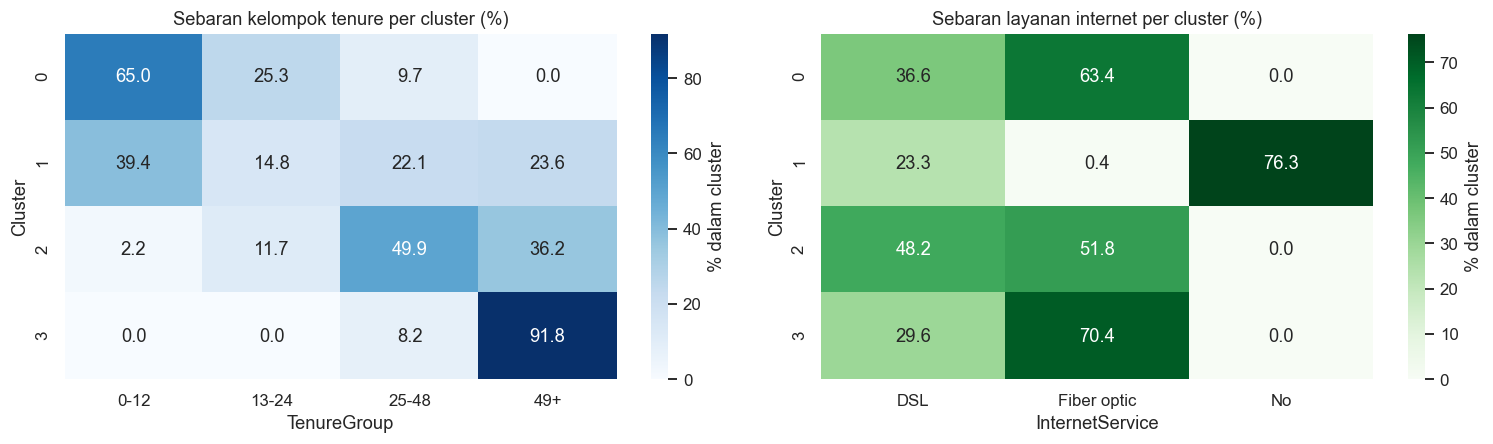

In [43]:
# Hubungan cluster dengan churn: uji chi-square + Cramér's V
ct = pd.crosstab(cdf["Cluster"], cdf["Churn"])
chi2, p, dof, _ = chi2_contingency(ct, correction=False)
v = cramers_v(ct)
print(f"Cluster vs Churn: chi2={chi2:.1f}, df={dof}, p={p:.2e}, Cramér's V={v:.3f}")
print("Catatan: cluster tidak dibentuk dari churn, sehingga asosiasi ini bukan sesuatu yang 'dipaksakan' oleh desain.")

# Perbandingan dengan variabel tunggal: apakah segmentasi menambah informasi?
v_contract = cramers_v(pd.crosstab(df["Contract"], df["Churn"]))
print(f"Pembanding — Cramér's V Contract vs Churn: {v_contract:.3f}")

# Sebaran tenure-group dan kontrak di tiap cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(pd.crosstab(cdf["Cluster"], cdf["TenureGroup"], normalize="index") * 100, annot=True, fmt=".1f",
            cmap="Blues", ax=axes[0], cbar_kws={"label": "% dalam cluster"})
axes[0].set_title("Sebaran kelompok tenure per cluster (%)")
sns.heatmap(pd.crosstab(cdf["Cluster"], cdf["InternetService"], normalize="index") * 100, annot=True, fmt=".1f",
            cmap="Greens", ax=axes[1], cbar_kws={"label": "% dalam cluster"})
axes[1].set_title("Sebaran layanan internet per cluster (%)")
plt.tight_layout(); save_fig("cluster_tenure_internet_distribution"); plt.show()

---
## Ekspor Hasil untuk Anggota Lain

In [44]:
out = cdf[["customerID", "Cluster", "ClusterName"]].copy()
out.to_csv(PROCESSED / "telco_clusters.csv", index=False)
save_tab(pd.DataFrame({"K": [K_FINAL], "Silhouette": [silhouette_score(X, cdf["Cluster"])],
                       "Davies-Bouldin": [davies_bouldin_score(X, cdf["Cluster"])]}), "cluster_final_metrics", index=False)

chk = pd.read_csv(PROCESSED / "telco_clusters.csv")
assert len(chk) == len(df) and chk["customerID"].is_unique and chk["Cluster"].between(0, K_FINAL - 1).all()
print("Tersimpan:", (PROCESSED / "telco_clusters.csv").resolve())
print("Jumlah file figures:", len(list(FIG.glob("*.png"))), "| tables:", len(list(TAB.glob("*.csv"))))

Tersimpan: C:\Users\melin\processed\telco_clusters.csv
Jumlah file figures: 22 | tables: 14


In [45]:
# Ringkasan cepat untuk dibawa ke laporan / notebook integrasi
top_cat = summary[summary["Jenis effect size"] == "Cramér's V"].sort_values("Effect size", ascending=False).head(5)
top_num = summary[summary["Jenis effect size"] == "Cliff's delta"].assign(a=lambda t: t["Effect size"].abs()).sort_values("a", ascending=False).head(3)
worst = prof["Churn rate (%)"].idxmax()

print(f"Churn rate keseluruhan : {overall_churn:.2f}%")
print("Asosiasi kategorikal terkuat (Cramér's V):",
      ", ".join(f"{a} ({b:.2f})" for a, b in zip(top_cat['Variabel'], top_cat['Effect size'])))
print("Perbedaan numerik terbesar (Cliff's delta)  :", ", ".join(f"{a} ({b:+.2f})" for a, b in zip(top_num['Variabel'], top_num['Effect size'])))
print(f"Cluster churn tertinggi: Cluster {worst} — {prof.loc[worst, 'Churn rate (%)']:.1f}% "
      f"({prof.loc[worst, 'Lift vs rata-rata']:.2f}x rata-rata), ukuran {prof.loc[worst, 'Persen']:.1f}% pelanggan")

Churn rate keseluruhan : 26.54%
Asosiasi kategorikal terkuat (Cramér's V): Contract (0.41), TenureGroup (0.35), OnlineSecurity (0.35), TechSupport (0.34), InternetService (0.32)
Perbedaan numerik terbesar (Cliff's delta)  : tenure (-0.48), TotalCharges (-0.30), MonthlyCharges (+0.24)
Cluster churn tertinggi: Cluster 0 — 50.3% (1.89x rata-rata), ukuran 29.7% pelanggan
